# Week 06: Model Parallelism

Week 5 took the Stage 1 codebase off one device. It split the **batch** across a mesh,
every device kept a full copy of the model, and an AllReduce glued the gradients back
together. That is data parallelism, and it buys you throughput. Read the sentence again
and notice what it does *not* buy you: **every device still holds the entire model.**
Data parallelism divides the work. It does not divide the model.

So there is a wall, and it is not a speed wall — it is an `OutOfMemoryError`. When one
copy of (parameters + Adam state + gradients + activations) does not fit on one device,
adding a hundred more devices changes nothing at all. Today is about the other axis: how
to split the **model** across devices (tensor parallel, pipeline parallel), how to stop
storing activations you can cheaply recompute (`jax.remat`), how to stop storing them at
32 bits when 16 will do, and how to stop replicating optimizer state that nobody needs
replicated (ZeRO). Four techniques, one question: *how big a model can you actually
train?*

This is **Lab 5**, and it **closes Stage 2** of the spine: the codebase now shards along
both axes — data *and* model — and you can put a number on the maximum model that fits.

## Learning Objectives

By the end of this session, you will be able to:
- Do the **memory arithmetic** of a training step — parameters, gradients, optimizer
  state, activations — and explain precisely which term data parallelism reduces (one)
  and which three it does not.
- Implement **Megatron-style tensor parallelism** with `shard_map`: column-parallel then
  row-parallel, exactly one AllReduce per block, verified bit-for-bit against the
  single-device model — and explain why the *backward* AllReduce appears for free.
- Compare the communication cost of **data vs tensor parallelism** quantitatively and say
  which one the interconnect will tolerate.
- Derive the **pipeline bubble fraction** $(P-1)/(M+P-1)$ and confirm it against a
  simulated schedule, exactly.
- Apply **activation checkpointing** (`jax.remat`), measure the memory it saves and the
  recompute it costs, and reproduce the $O(\sqrt{L})$ checkpointing result numerically.
- Use **`jax.checkpoint_policies`** to buy most of the memory saving for almost none of
  the recompute.
- Explain **mixed precision** — why activations can be `bfloat16` and why the master
  weights cannot.
- Explain **ZeRO** as "stop replicating what nobody reads", and shard optimizer state
  across a mesh, measuring the per-device bytes drop by exactly $P$.
- Report Lab 5's metrics: **per-device memory · examples/sec · compile time · maximum
  feasible width · recompute overhead**.


In [1]:
import os
# EIGHT fake devices, faked BEFORE jax is imported. This is the whole reason the
# multi-device cells below execute at all on a CPU-only laptop.
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=8"

import time
import functools

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import equinox as eqx
import optax
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P

key = jax.random.key(0)
rng = np.random.default_rng(0)

print("jax     ", jax.__version__)
print("equinox ", eqx.__version__)
print("optax   ", optax.__version__)
print("devices :", len(jax.devices()), "x", jax.devices()[0].device_kind)
print(jax.devices())

jax      0.10.2
equinox  0.13.8
optax    0.2.8
devices : 8 x cpu
[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3), CpuDevice(id=4), CpuDevice(id=5), CpuDevice(id=6), CpuDevice(id=7)]


> **Read the numbers in this notebook the right way.** Those eight "devices" are eight
> slices of one CPU. As in Week 5, the **sharding semantics are real** — `shard_map` really
> splits the arrays, `psum` really is an AllReduce, the math really comes out identical to
> the single-device model, and a mistake really does produce a wrong answer. What is **not**
> real is any performance number that depends on eight independent chips existing: there is
> no interconnect here, so communication is a memcpy, and "8× the memory" is eight slices of
> the same RAM.
>
> That matters especially this week, because this week's headline metric is **memory**, and
> we cannot honestly measure peak device memory on a device that does not exist. So we do
> not pretend to. Where this notebook reports memory it reports one of two things, and it
> always says which:
>
> | number | where it comes from | is it real? |
> |--------|--------------------|-------------|
> | **compiler-reported bytes** | `jax.jit(f).lower(...).compile().memory_analysis()` — XLA's buffer assignment for the *compiled program*, reported **per device** | **Yes.** It is what the compiler will actually allocate, and it is a property of the program, not of this laptop. |
> | **residual bytes** | the constants of the linearized program (`jax.linearize` → jaxpr consts) — exactly the activations reverse-mode AD must keep alive | **Yes, and exactly.** It is a count, not an estimate, and it is what `remat` changes. |
> | ~~peak GPU memory~~ | `jax.local_devices()[0].memory_stats()` | **Not available here.** That is the GPU-node half of Lab 5. |
>
> Wall-clock is the number to distrust today. Report it, name the device, and do not build
> an argument on it.


---

## 1. Where the memory goes — and what data parallelism does about it

Start with arithmetic, not code. A training step for a model with $N$ parameters, in
float32, with Adam, needs to keep alive:

| what | bytes per parameter | data parallelism over $P$ devices? |
|------|--------------------:|-----------------------------------|
| parameters $\theta$ | 4 | **replicated** — every device holds all $N$ |
| gradients $g$ | 4 | **replicated** — the AllReduce output is the same on every device |
| Adam first moment $m$ | 4 | **replicated** |
| Adam second moment $v$ | 4 | **replicated** |
| **persistent subtotal** | **16** | **divided by 1** |
| activations | $\propto$ batch $\times$ width $\times$ depth | **divided by $P$** (each device sees $B/P$ examples) |

That table is the entire motivation for this week. Adam costs **16 bytes per parameter**
before a single activation is stored, and data parallelism reduces **none** of it. The one
term DP does divide is the activations — which is why DP works beautifully right up until
the moment it doesn't.

$$M_{\text{per device}}^{\text{DP}} = \underbrace{16N}_{\text{unchanged by }P} +
\underbrace{\frac{A(B)}{P}}_{\text{divided by }P}$$

This is a simplified memory model assuming FP32 Adam, fully replicated training states, and activation memory scaling linearly with the local batch size. Actual peak memory also includes temporary buffers, communication overhead, and compiler-dependent allocations. 

Let us put numbers on it before we write any parallelism.


In [2]:
def state_bytes(n_params, opt="adam", dtype_bytes=4):
    # persistent training state, in bytes, for n_params parameters
    slots = {"sgd": 2, "sgd+momentum": 3, "adam": 4}[opt]   # theta, g, [m], [v]
    return slots * dtype_bytes * n_params


print(f"{'model':>22}  {'params':>15}  {'SGD':>8}  {'SGD+mom':>8}  {'Adam':>8}  "
      f"{'80GB cards for Adam':>20}")
print("-" * 90)
models = [("Week 3 ResNet (toy)", 1.1e4), ("ResNet-50", 25.6e6), ("BERT-large", 340e6),
          ("GPT-2 XL", 1.5e9), ("Llama-3 8B", 8.0e9), ("Llama-3 70B", 70e9)]
for name, n in models:
    row = "  ".join(f"{state_bytes(n, o) / 1e9:>8.2f}" for o in ["sgd", "sgd+momentum", "adam"])
    cards = state_bytes(n, "adam") / 1e9 / (0.8 * 80)      # 80 GB card, 80% usable
    print(f"{name:>22}  {n:>15,.0f}  {row}  {max(cards, 0.001):>20.2f}")
print("\n(GB of PERSISTENT state -- parameters + gradients + optimizer moments. Activations")
print(" are on top of this, and they scale with the batch.)")
print()
print("Read the last column carefully. It says how many 80 GB cards' worth of memory the")
print("state occupies -- NOT how many cards make it trainable. Under data parallelism a")
print("value above 1.0 means the model does not train AT ALL, on any number of GPUs:")
for name, n in models:
    cards = state_bytes(n, "adam") / 1e9 / (0.8 * 80)
    verdict = "trains under plain DP" if cards <= 1 else "IMPOSSIBLE under plain DP, at any P"
    print(f"   {name:>22}: {verdict}")
print("\n^ and none of those verdicts change if you add a second GPU. Or a thousand.")

                 model           params       SGD   SGD+mom      Adam   80GB cards for Adam
------------------------------------------------------------------------------------------
   Week 3 ResNet (toy)           11,000      0.00      0.00      0.00                  0.00
             ResNet-50       25,600,000      0.20      0.31      0.41                  0.01
            BERT-large      340,000,000      2.72      4.08      5.44                  0.09
              GPT-2 XL    1,500,000,000     12.00     18.00     24.00                  0.38
            Llama-3 8B    8,000,000,000     64.00     96.00    128.00                  2.00
           Llama-3 70B   70,000,000,000    560.00    840.00   1120.00                 17.50

(GB of PERSISTENT state -- parameters + gradients + optimizer moments. Activations
 are on top of this, and they scale with the batch.)

Read the last column carefully. It says how many 80 GB cards' worth of memory the
state occupies -- NOT how many cards make it 

### Don't take my word for it — measure it

Let us make the claim falsifiable. Build the Stage 1 codebase (Week 3's Equinox ResNet,
Week 4's fast step), shard the **batch** across a mesh exactly as Week 5 did, and ask the
compiler how many bytes each device needs — for $P = 1, 2, 4, 8$.

If data parallelism divided the model, the per-device argument bytes would fall. Watch
them not fall.


In [3]:
# ---- The Stage 1 codebase, carried forward from Weeks 3-4 (unchanged) ----
class ResBlock(eqx.Module):
    conv1: eqx.nn.Conv2d
    bn1: eqx.nn.BatchNorm
    conv2: eqx.nn.Conv2d
    bn2: eqx.nn.BatchNorm

    def __init__(self, channels, key, bn_momentum=0.9):
        k1, k2 = jax.random.split(key)
        self.conv1 = eqx.nn.Conv2d(channels, channels, 3, padding=1, use_bias=False, key=k1)
        self.bn1 = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)
        self.conv2 = eqx.nn.Conv2d(channels, channels, 3, padding=1, use_bias=False, key=k2)
        self.bn2 = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)

    def __call__(self, x, state):
        h, state = self.bn1(self.conv1(x), state)
        h = jax.nn.relu(h)
        h, state = self.bn2(self.conv2(h), state)
        return jax.nn.relu(x + h), state


class ResNet(eqx.Module):
    stem: eqx.nn.Conv2d
    stem_bn: eqx.nn.BatchNorm
    blocks: list
    head: eqx.nn.Linear

    def __init__(self, key, channels=16, n_blocks=2, n_classes=4, bn_momentum=0.9):
        ks = jax.random.split(key, n_blocks + 2)
        self.stem = eqx.nn.Conv2d(3, channels, 3, stride=2, padding=1, use_bias=False, key=ks[0])
        self.stem_bn = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)
        self.blocks = [ResBlock(channels, ks[i + 1], bn_momentum) for i in range(n_blocks)]
        self.head = eqx.nn.Linear(channels, n_classes, key=ks[-1])

    def __call__(self, x, state):
        x, state = self.stem_bn(self.stem(x), state)
        x = jax.nn.relu(x)
        for block in self.blocks:
            x, state = block(x, state)
        x = jnp.mean(x, axis=(1, 2))
        return self.head(x), state


def batched_forward(model, state, x):
    return eqx.filter_vmap(lambda m, s, xi: m(xi, s), in_axes=(None, None, 0),
                           out_axes=(0, None), axis_name="batch")(model, state, x)


def resnet_loss(model, state, x, y):
    logits, state = batched_forward(model, state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state


# ---- synthetic CIFAR-shaped data (the harness has no network; the real lab uses Grain) ----
N_CLASSES, IMG = 4, 32

def make_templates(key, n_classes=N_CLASSES, size=IMG):
    lo = jax.random.normal(key, (n_classes, 3, 8, 8))
    return jax.image.resize(lo, (n_classes, 3, size, size), method="linear")

def make_data(n, key, templates, noise=1.0):
    k_lab, k_noise = jax.random.split(key)
    labels = jax.random.randint(k_lab, (n,), 0, templates.shape[0])
    return templates[labels] + jax.random.normal(k_noise, (n,) + templates.shape[1:]) * noise, labels

TEMPLATES = make_templates(jax.random.key(7))
X_tr, Y_tr = make_data(1024, jax.random.key(1), TEMPLATES)

model0, bn0 = eqx.nn.make_with_state(ResNet)(jax.random.key(1))
params0, static0 = eqx.partition(model0, eqx.is_inexact_array)
n_params = sum(p.size for p in jax.tree.leaves(params0))
print(f"Stage 1 ResNet: {n_params:,} parameters | data {X_tr.shape}")
print(f"four states kept separate, as since Week 3: params | opt state | bn state | PRNG")

Stage 1 ResNet: 9,876 parameters | data (1024, 3, 32, 32)
four states kept separate, as since Week 3: params | opt state | bn state | PRNG


In [4]:
# ---- Week 5's data parallelism: shard the BATCH over a 'data' mesh axis ----
optimizer = optax.adamw(1e-3)
opt0 = optimizer.init(params0)
BATCH = 128


def dp_step(params, bn_state, opt_state, x, y):
    def _loss(p, s):
        return resnet_loss(eqx.combine(p, static0), s, x, y)
    (loss, bn_state), grads = jax.value_and_grad(_loss, has_aux=True)(params, bn_state)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    return eqx.apply_updates(params, updates), bn_state, opt_state, loss


def per_device_bytes(tree):
    # exact: how many bytes of THIS tree land on ONE device, given its sharding
    return sum(int(np.prod(l.addressable_shards[0].data.shape)) * l.dtype.itemsize
               for l in jax.tree.leaves(tree) if hasattr(l, "addressable_shards"))


print(f"{'devices P':>10}  {'params+optimizer+BN KB/dev':>19}  {'batch KB/dev':>13}  "
      f"{'XLA temp KB/dev':>19}  {'params/device':>14}")
print("-" * 84)
dp_rows = []
for Pn in [1, 2, 4, 8]:
    mesh_dp = jax.make_mesh((Pn,), ("data",), devices=jax.devices()[:Pn])
    rep = NamedSharding(mesh_dp, P())              # model: REPLICATED
    bat = NamedSharding(mesh_dp, P("data"))        # data:  SHARDED on the batch axis

    p_d = jax.device_put(params0, rep)
    s_d = jax.device_put(bn0, rep)
    o_d = jax.device_put(opt0, rep)
    x_d = jax.device_put(X_tr[:BATCH], bat)
    y_d = jax.device_put(Y_tr[:BATCH], bat)

    c = jax.jit(dp_step).lower(p_d, s_d, o_d, x_d, y_d).compile()
    temp_kb = c.memory_analysis().temp_size_in_bytes / 1e3
    # split the ARGUMENTS into their two very different halves
    model_kb = (per_device_bytes(p_d) + per_device_bytes(o_d) + per_device_bytes(s_d)) / 1e3 # M ~ 12N + M_BN
    batch_kb = (per_device_bytes(x_d) + per_device_bytes(y_d)) / 1e3
    dp_rows.append((Pn, model_kb, batch_kb, temp_kb))
    print(f"{Pn:>10}  {model_kb:>19.2f}  {batch_kb:>13.2f}  {temp_kb:>19.2f}  {n_params:>14,}")

print("\nparams+Adam = the model's persistent state (exact, from each array's local shard)")
print("batch       = this device's slice of the data")
print("activations = XLA's temp buffers for the step (compiler-reported)")
print()
print(f"model state, P=1 -> P=8 : {dp_rows[0][1]:.2f} -> {dp_rows[-1][1]:.2f} KB/device "
      f"({dp_rows[0][1] / dp_rows[-1][1]:.2f}x)   <- IDENTICAL. The model did not shrink.")
print(f"activations, P=1 -> P=8 : {dp_rows[0][3]:.2f} -> {dp_rows[-1][3]:.2f} KB/device "
      f"({dp_rows[0][3] / max(dp_rows[-1][3], 1e-9):.2f}x)   <- divided by P, exactly.")
print(f"batch,       P=1 -> P=8 : {dp_rows[0][2]:.2f} -> {dp_rows[-1][2]:.2f} KB/device "
      f"({dp_rows[0][2] / max(dp_rows[-1][2], 1e-9):.2f}x)   <- divided by P, exactly.")
print(f"\ncheck: 16 bytes/param x {n_params:,} params = "
      f"{16 * n_params / 1e3:.2f} KB, on every device, at every P.")

 devices P  params+optimizer+BN KB/dev   batch KB/dev      XLA temp KB/dev   params/device
------------------------------------------------------------------------------------
         1               119.18        1573.38             49807.75           9,876
         2               119.18         786.69             24904.34           9,876
         4               119.18         393.34             12452.43           9,876
         8               119.18         196.67              6226.51           9,876

params+Adam = the model's persistent state (exact, from each array's local shard)
batch       = this device's slice of the data
activations = XLA's temp buffers for the step (compiler-reported)

model state, P=1 -> P=8 : 119.18 -> 119.18 KB/device (1.00x)   <- IDENTICAL. The model did not shrink.
activations, P=1 -> P=8 : 49807.75 -> 6226.51 KB/device (8.00x)   <- divided by P, exactly.
batch,       P=1 -> P=8 : 1573.38 -> 196.67 KB/device (8.00x)   <- divided by P, exactly.

check:

> **Observe:** the measurement confirms that replicated model and optimizer states remain unchanged as the number of devices increases, while batch storage and compiler-reported temporary memory decrease apprximately as 1/P in this experiment. The measured persistent state excludes gradients, which are transient during the training step. 
> 8 divided the **activation** memory by exactly 8 and the **batch** memory by exactly 8 —
> each device only forwards $B/8$ examples — and left the **parameter + optimizer** memory
> at precisely $16N$ bytes, unchanged, because every device still holds a full copy of the
> model and a full copy of Adam's two moments.
>
> This is the wall, stated precisely: data parallelism is a **throughput** technique, not a
> **capacity** technique. $16N$ bytes per device is $16N$ bytes per device no matter how
> many devices you buy. If your model does not fit, your cluster does not help — and every
> technique in the rest of this notebook exists to attack a different term of
> $M = 16N + A(B)$.
>
> Note also the balance you just measured: on *this* toy ResNet, activations dominate the
> parameters. That is what it looks like when a model is small and a batch is large — and it
> is exactly the regime where `remat` (§5) is the right tool. At 70B parameters the balance
> inverts and ZeRO (§7) and tensor parallelism (§2) become the right tools. Which technique
> is "the answer" is a question about *your* $N$ and *your* $B$, and the only way to know is
> to measure both terms. Which we just did.


---

## 2. Tensor parallelism, Megatron style

The idea in one sentence: **a matmul is already parallel — split the weight matrix, not the
batch.**

Take the block at the heart of every transformer (and of every wide MLP):

$$Z = \operatorname{GeLU}(X A)\, B, \qquad X \in \mathbb{R}^{B \times d},\quad
A \in \mathbb{R}^{d \times h},\quad B \in \mathbb{R}^{h \times d}$$

with $h = 4d$, so $A$ and $B$ hold almost all the parameters. There are two ways to split a
matmul, and the whole trick is that **Megatron uses both, in the right order**:

**Column-parallel** ($A$ split along its *columns*, $A = [A_1 \,|\, \cdots \,|\, A_P]$):

$$XA = [\,XA_1 \,|\, \cdots \,|\, XA_P\,]$$

Device $i$ needs all of $X$ and produces the $i$-th column block of $Y = XA$. And here is
the point that makes it work: **GeLU is elementwise**, so
$\operatorname{GeLU}([Y_1|\cdots|Y_P]) = [\operatorname{GeLU}(Y_1)|\cdots|\operatorname{GeLU}(Y_P)]$.
The nonlinearity needs no communication. If you split $A$ along *rows* instead, you would
have to sum the partial products **before** the GeLU — an AllReduce in the middle of the
block.

**Row-parallel** ($B$ split along its *rows*, $B = [B_1; \cdots; B_P]$):

$$Y B = \sum_{i=1}^{P} Y_i B_i$$

Device $i$ already holds $Y_i$ — the very block column that column-parallel handed it — and
produces a *partial sum* of the full-shape output. One `psum` finishes it.

```
        column-parallel A            row-parallel B
   X  --------> [X A_i] --GeLU--> Y_i --------> Y_i B_i  --psum--> Z
(replicated)   (sharded, h/P)   (sharded)     (partial sums)   (replicated)
                     ^                                  ^
              no comm needed                   ONE AllReduce per block
```

Column-then-row is the pairing that puts zero communication between the two matmuls
and exactly one AllReduce at the end. That is Megatron-LM's contribution, and it looks
obvious only in retrospect.


In [5]:
mesh = jax.make_mesh((8,), ("model",))
Pm = mesh.shape["model"]
print("mesh:", mesh)

D_MODEL, D_HIDDEN, B_TOK = 256, 4 * 256, 64
kA, kB, kX = jax.random.split(jax.random.key(0), 3)
A_full = jax.random.normal(kA, (D_MODEL, D_HIDDEN)) / jnp.sqrt(D_MODEL)
B_full = jax.random.normal(kB, (D_HIDDEN, D_MODEL)) / jnp.sqrt(D_HIDDEN)
X_full = jax.random.normal(kX, (B_TOK, D_MODEL))


def block_ref(x, a, b):
    # the single-device ground truth -- the thing we must reproduce EXACTLY
    return jax.nn.gelu(x @ a) @ b


put = lambda arr, spec: jax.device_put(arr, NamedSharding(mesh, spec))

X_rep = put(X_full, P())                    # X replicated
A_col = put(A_full, P(None, "model"))       # A split along COLUMNS -> (d, h/P) per device
B_row = put(B_full, P("model", None))       # B split along ROWS    -> (h/P, d) per device

print(f"\nA global {A_full.shape} -> per-device {A_col.addressable_shards[0].data.shape}   (column-parallel)")
print(f"B global {B_full.shape} -> per-device {B_row.addressable_shards[0].data.shape}   (row-parallel)")
print(f"X global {X_full.shape} -> per-device {X_rep.addressable_shards[0].data.shape}   (replicated)")

mesh: Mesh('model': 8, axis_types=(Explicit,))



A global (256, 1024) -> per-device (256, 128)   (column-parallel)
B global (1024, 256) -> per-device (128, 256)   (row-parallel)
X global (64, 256) -> per-device (64, 256)   (replicated)


In [6]:
@jax.jit
def block_tp(x, a, b):
    def f(x, a, b):
        # Inside shard_map every array is the LOCAL shard. Shapes below are per-device.
        y = jax.nn.gelu(x @ a)          # (B, h/P)  column-parallel; GeLU is elementwise -> no comm
        z_partial = y @ b               # (B, d)    row-parallel -> a PARTIAL sum
        return jax.lax.psum(z_partial, "model")   # the ONE AllReduce of the block
    return jax.shard_map(f, mesh=mesh,
                         in_specs=(P(), P(None, "model"), P("model", None)),
                         out_specs=P())(x, a, b)


z_ref = block_ref(X_full, A_full, B_full)
z_tp = block_tp(X_rep, A_col, B_row)

print("single device :", z_ref.shape)
print("8-way tensor  :", z_tp.shape, "  sharding:", z_tp.sharding.spec)
print(f"\nmax |difference| : {float(jnp.abs(z_ref - z_tp).max()):.3e}")
print("allclose         :", bool(jnp.allclose(z_ref, z_tp, atol=1e-4)))
print("\n^ THE test. Model parallelism is a claim about the machine, never about the math:")
print("  the sharded model must compute the same function as the unsharded one.")

single device : (64, 256)
8-way tensor  : (64, 256)   sharding: P(None, None)

max |difference| : 2.980e-06
allclose         : True

^ THE test. Model parallelism is a claim about the machine, never about the math:
  the sharded model must compute the same function as the unsharded one.


### The backward pass, which you did not have to write

Here is the part that makes JAX pleasant. In Megatron the backward pass needs its own
collective — the gradient flowing back into a row-parallel layer must be broadcast, and the
gradient flowing back out of a column-parallel layer must be summed. In the original
implementation those are hand-written `f`/`g` conjugate operators.

We wrote none of that. `jax.lax.psum` is a linear operation and AD knows its transpose:
the transpose of "sum across devices" is "broadcast to all devices", and vice versa.
Differentiating the `shard_map`ped block therefore emits the correct backward collectives
automatically — **and the gradients come back sharded exactly like the parameters they
belong to**, which is what you need if you are ever going to apply an update without
gathering the model.


In [7]:
def tp_loss(a, b, x):
    return jnp.sum(block_tp(x, a, b) ** 2)

def ref_loss(a, b, x):
    return jnp.sum(block_ref(x, a, b) ** 2)


gA_tp, gB_tp = jax.jit(jax.grad(tp_loss, argnums=(0, 1)))(A_col, B_row, X_rep)
gA_rf, gB_rf = jax.jit(jax.grad(ref_loss, argnums=(0, 1)))(A_full, B_full, X_full)

print(f"{'gradient':>10}  {'sharding spec':>22}  {'per-device shape':>18}  {'matches 1-device?':>18}")
print("-" * 76)
for name, g_tp, g_rf in [("dL/dA", gA_tp, gA_rf), ("dL/dB", gB_tp, gB_rf)]:
    ok = bool(jnp.allclose(g_tp, g_rf, rtol=1e-4, atol=1e-3))
    print(f"{name:>10}  {str(g_tp.sharding.spec):>22}  "
          f"{str(g_tp.addressable_shards[0].data.shape):>18}  {str(ok):>18}")

print("\ndL/dA is column-sharded, dL/dB is row-sharded -- IDENTICAL to the parameters.")
print("Nobody ever materializes a full-size gradient. Not one line of collective code")
print("was written for the backward pass: AD transposed the psum for us.")

hlo = jax.jit(jax.grad(tp_loss, argnums=(0, 1))).lower(A_col, B_row, X_rep).as_text()
collectives = sorted({op for op in ["all-reduce", "all-gather", "reduce-scatter", "all-to-all"]
                      if op in hlo or op.replace("-", "_") in hlo})
print(f"\ncollectives XLA emitted for the BACKWARD pass: {collectives}")

  gradient           sharding spec    per-device shape   matches 1-device?
----------------------------------------------------------------------------
     dL/dA        P(None, 'model')          (256, 128)                True
     dL/dB        P('model', None)          (128, 256)                True

dL/dA is column-sharded, dL/dB is row-sharded -- IDENTICAL to the parameters.
Nobody ever materializes a full-size gradient. Not one line of collective code
was written for the backward pass: AD transposed the psum for us.

collectives XLA emitted for the BACKWARD pass: ['all-reduce']


> **Observe:** the sharded block reproduces the single-device block to floating-point noise
> ($\sim10^{-6}$), forward *and* backward, and the parameter gradients come back with the same
> `PartitionSpec` as the parameters. That last fact is what makes tensor parallelism
> composable with an optimizer: `optax.adamw` is elementwise, so if $\theta$ and $g$ are
> sharded the same way, $m$, $v$ and the update are too — and the whole persistent state is
> divided by $P$ without anybody asking for it. We will make that explicit in §7.
>
> The lesson about the *ordering* is the one to carry: column-then-row is not a convention,
> it is the arrangement in which the elementwise nonlinearity sits exactly where no
> communication is needed. Exercise 1 makes you pay for getting it wrong.


### And the point of all this: the memory actually moved

§1 measured data parallelism failing to shrink the model. Run the same measurement on the
tensor-parallel block and watch the number that would not move, move.


In [8]:
def block_params_per_device(a, b):
    return (int(np.prod(a.addressable_shards[0].data.shape)) * a.dtype.itemsize +
            int(np.prod(b.addressable_shards[0].data.shape)) * b.dtype.itemsize)


A_rep, B_rep = put(A_full, P()), put(B_full, P())
n_block = A_full.size + B_full.size

print(f"one MLP block: A {A_full.shape} + B {B_full.shape} = {n_block:,} parameters")
print(f"\n{'scheme':>26}  {'params/device':>14}  {'weights KB/dev':>15}  {'+ Adam KB/dev':>14}")
print("-" * 76)
for name, (a, b) in [("data parallel (replicated)", (A_rep, B_rep)),
                     ("tensor parallel (sharded)", (A_col, B_row))]:
    wb = block_params_per_device(a, b)
    print(f"{name:>26}  {wb // 4:>14,}  {wb / 1e3:>15.2f}  {4 * wb / 1e3:>14.2f}")

print(f"\nreduction: exactly {Pm}x -- the mesh size. Not 'about' {Pm}x: the arrays are")
print("partitioned, so each device holds 1/P of the elements and there is no rounding.")
print("\nAnd because the gradients came back sharded (the table above), Adam's m and v")
print("are sharded too, for free: the ENTIRE 16 bytes/param is divided by P. Tensor")
print("parallelism gets ZeRO-3's memory profile as a side effect of splitting the matmul.")
print("Section 7 gets there the other way -- without splitting any matmul at all.")

one MLP block: A (256, 1024) + B (1024, 256) = 524,288 parameters

                    scheme   params/device   weights KB/dev   + Adam KB/dev
----------------------------------------------------------------------------
data parallel (replicated)         524,288          2097.15         8388.61
 tensor parallel (sharded)          65,536           262.14         1048.58

reduction: exactly 8x -- the mesh size. Not 'about' 8x: the arrays are
partitioned, so each device holds 1/P of the elements and there is no rounding.

And because the gradients came back sharded (the table above), Adam's m and v
are sharded too, for free: the ENTIRE 16 bytes/param is divided by P. Tensor
parallelism gets ZeRO-3's memory profile as a side effect of splitting the matmul.
Section 7 gets there the other way -- without splitting any matmul at all.


### 🔬 Exercise 1

**Exercise:** Megatron's column-then-row pairing looks arbitrary until you try the
alternative. Shard **both** $A$ and $B$ along their columns and make it work.

1. Work out what goes wrong: with $A$ column-sharded, device $i$ holds $Y_i$ (columns of
   $Y$); but with $B$ *also* column-sharded, device $i$ holds *rows* $B$ that it does not
   have the matching columns of $Y$ for. What collective repairs it, and on what tensor?
2. Implement it with `jax.lax.all_gather` inside `shard_map` and verify it against
   `block_ref`.
3. Count the bytes each device moves per block, for both schemes, using the ring costs from
   Week 5: AllReduce moves $2\frac{P-1}{P}|v|$ bytes per device, AllGather moves
   $\frac{P-1}{P}|v|$. Which is cheaper, and by what factor?


In [9]:
# --- Reference solution (instructor: blank this out for students) ---

B_col = put(B_full, P(None, "model"))        # B split along COLUMNS: the "wrong" way

@jax.jit
def block_naive(x, a, b):
    def f(x, a, b):
        y = jax.nn.gelu(x @ a)                                        # (B, h/P) -- sharded
        # PROBLEM: b is (h, d/P) -- it needs ALL h rows of y, but we only have h/P of them.
        y_full = jax.lax.all_gather(y, "model", axis=1, tiled=True)   # (B, h) -- COLLECTIVE #1
        z_part = y_full @ b                                           # (B, d/P) -- column-sharded out
        # and the next block needs a replicated (B, d) input, so:
        return jax.lax.all_gather(z_part, "model", axis=1, tiled=True)  # (B, d) -- COLLECTIVE #2
    return jax.shard_map(f, mesh=mesh, in_specs=(P(), P(None, "model"), P(None, "model")),
                         out_specs=P(), check_vma=False)(x, a, b)


z_naive = block_naive(X_rep, A_col, B_col)
print("naive (column, column) matches single device:",
      bool(jnp.allclose(z_naive, z_ref, atol=1e-4)),
      f"  max|diff| {float(jnp.abs(z_naive - z_ref).max()):.2e}")
print("It is CORRECT. It is just expensive. Count the bytes:\n")

f32 = 4
ring_allreduce = lambda nbytes, p: 2 * (p - 1) / p * nbytes
ring_allgather = lambda nbytes, p: (p - 1) / p * nbytes

hidden_bytes = B_TOK * D_HIDDEN * f32          # |Y| : (B, h)
out_bytes = B_TOK * D_MODEL * f32              # |Z| : (B, d)

megatron = ring_allreduce(out_bytes, Pm)
naive = ring_allgather(hidden_bytes, Pm) + ring_allgather(out_bytes, Pm)

print(f"{'scheme':>28}  {'collectives':>28}  {'bytes/device/block':>19}")
print("-" * 82)
print(f"{'Megatron (column then row)':>28}  {'1 x AllReduce on (B, d)':>28}  {megatron:>19,.0f}")
print(f"{'naive (column then column)':>28}  {'2 x AllGather on (B,h)+(B,d)':>28}  {naive:>19,.0f}")
print(f"\nnaive / Megatron = {naive / megatron:.2f}x more bytes on the wire, per block, forever.")
print(f"\nWhy: the naive scheme must move the WIDE tensor (h = {D_HIDDEN} = 4d), while Megatron")
print(f"only ever moves the NARROW one (d = {D_MODEL}). Column-then-row keeps the 4x-wider")
print("hidden activation entirely device-local. THAT is the design, and it is worth")
print(f"{naive / megatron:.1f}x of your interconnect on every block of every step.")

naive (column, column) matches single device: True   max|diff| 2.38e-07
It is CORRECT. It is just expensive. Count the bytes:

                      scheme                   collectives   bytes/device/block
----------------------------------------------------------------------------------
  Megatron (column then row)       1 x AllReduce on (B, d)              114,688
  naive (column then column)  2 x AllGather on (B,h)+(B,d)              286,720

naive / Megatron = 2.50x more bytes on the wire, per block, forever.

Why: the naive scheme must move the WIDE tensor (h = 1024 = 4d), while Megatron
only ever moves the NARROW one (d = 256). Column-then-row keeps the 4x-wider
hidden activation entirely device-local. THAT is the design, and it is worth
2.5x of your interconnect on every block of every step.


---

## 3. What tensor parallelism costs: TP vs DP

Tensor parallelism divides the model. Nothing is free; the bill arrives on the
interconnect. Compare the two schemes over one training step of an $L$-block model, using
Week 5's ring costs (bytes moved **per device**):

| | data parallel | tensor parallel |
|---|---|---|
| what is split | the batch | every weight matrix |
| params per device | $N$ (**all of them**) | $N/P$ |
| collective | 1 AllReduce on the gradients | 1 AllReduce per block, **forward and backward** |
| how often | **once per step** | $2L$ **times per step** |
| bytes per device per step | $2\frac{P-1}{P} \cdot 4N$ | $2L \cdot 2\frac{P-1}{P} \cdot 4Bd$ |
| depends on | model size $N$ | batch $\times$ width $\times$ depth |
| tolerates a slow link? | **yes** — one big message, overlappable with the backward pass | **no** — $2L$ blocking messages *inside* the step |

Read the last row twice. The DP typically communicates gradients through one or more AllReduce operations, often overlapped with backward computation. The TP AllReduce is
**latency on the critical path**: nothing in the block can proceed until the sum lands.
That is why in real clusters **tensor parallelism stays inside one node** (NVLink,
hundreds of GB/s) and **data parallelism spans nodes** (InfiniBand or Ethernet). The
topology is not an accident, it is this table.


In [10]:
def dp_bytes_per_step(n_params, p, f32=4):
    return 2 * (p - 1) / p * f32 * n_params                 # ONE gradient AllReduce

def tp_bytes_per_step(n_layers, batch, d_model, p, f32=4):
    per_block = 2 * (p - 1) / p * f32 * batch * d_model     # one AllReduce, (B, d)
    return 2 * n_layers * per_block                         # x2: forward AND backward

# a GPT-2-XL-ish block stack, and a realistic per-device micro-batch
L_BLOCKS, D_MDL, PDEV = 48, 1600, 8
N_PARAM = L_BLOCKS * 12 * D_MDL ** 2                        # ~12 d^2 params per transformer block

print(f"model: {L_BLOCKS} blocks, d_model = {D_MDL}, N = {N_PARAM / 1e6:.0f}M params, P = {PDEV}")
print(f"\n{'micro-batch (tokens)':>21}  {'DP bytes/step':>15}  {'TP bytes/step':>15}  {'TP/DP':>8}")
print("-" * 66)
batches = [64, 256, 1024, 4096, 16384]
dp_b = [dp_bytes_per_step(N_PARAM, PDEV) for _ in batches]
tp_b = [tp_bytes_per_step(L_BLOCKS, b, D_MDL, PDEV) for b in batches]
for b, d, t in zip(batches, dp_b, tp_b):
    print(f"{b:>21,}  {d / 1e6:>12.1f} MB  {t / 1e6:>12.1f} MB  {t / d:>7.2f}x")

crossover = dp_b[0] / (tp_bytes_per_step(L_BLOCKS, 1, D_MDL, PDEV))
print(f"\ncrossover: TP moves more than DP above ~{crossover:,.0f} tokens per micro-batch.")
print("DP's cost is FIXED by the model size; TP's grows with the batch. And TP's cost is")
print(f"spread over {2 * L_BLOCKS} BLOCKING messages per step, versus DP's 1 overlappable one.")

model: 48 blocks, d_model = 1600, N = 1475M params, P = 8

 micro-batch (tokens)    DP bytes/step    TP bytes/step     TP/DP
------------------------------------------------------------------
                   64       10321.9 MB          68.8 MB     0.01x
                  256       10321.9 MB         275.3 MB     0.03x
                1,024       10321.9 MB        1101.0 MB     0.11x
                4,096       10321.9 MB        4404.0 MB     0.43x
               16,384       10321.9 MB       17616.1 MB     1.71x

crossover: TP moves more than DP above ~9,600 tokens per micro-batch.
DP's cost is FIXED by the model size; TP's grows with the batch. And TP's cost is
spread over 96 BLOCKING messages per step, versus DP's 1 overlappable one.


one training step, micro-batch 16384 tokens, P = 8
                        link    GB/s    DP (1 msg)   TP (96 msgs)
------------------------------------------------------------------
         NVLink (intra-node)  300.00      34.41 ms       58.91 ms
 InfiniBand HDR (inter-node)   25.00     412.88 ms      705.12 ms
    10 GbE (a cheap cluster)    1.25    8257.59 ms    14097.66 ms

and now the column the byte count does NOT show:
                                                      DP                          TP
           messages per step                           1                          96
       on the critical path?  no -- overlaps the backward     YES -- the block stalls

The DP AllReduce for layer i can start the moment layer i's gradient exists,
while layers i-1..1 are still computing. Its cost is largely HIDDEN. The TP
AllReduce cannot be hidden behind anything: the next op needs its result. So the
ms columns above understate DP's advantage and overstate TP's, and the real
c

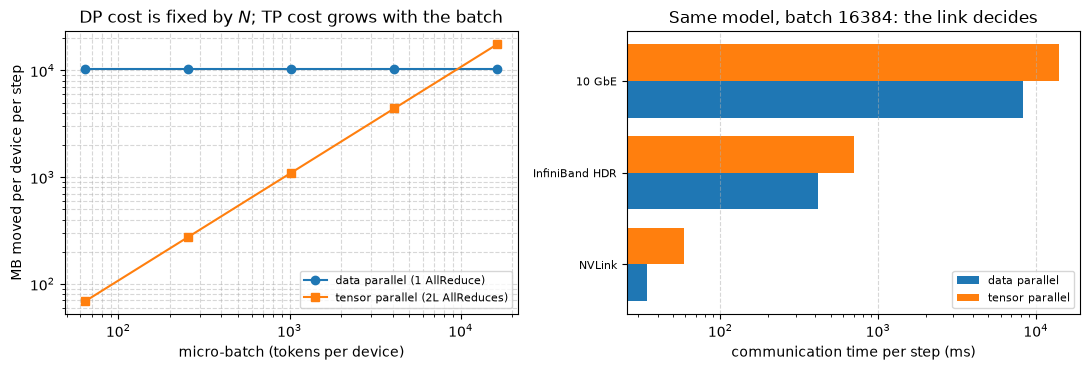

In [11]:
# What does that cost in TIME? Model a link as latency + bandwidth.
def link_time(nbytes, n_messages, gbps, latency_us):
    return n_messages * latency_us * 1e-6 + nbytes / (gbps * 1e9)


links = [("NVLink (intra-node)", 300, 2.0), ("InfiniBand HDR (inter-node)", 25, 5.0),
         ("10 GbE (a cheap cluster)", 1.25, 50.0)]
batch = 16384                 # past the crossover computed above
n_dp_bytes = dp_bytes_per_step(N_PARAM, PDEV)
n_tp_bytes = tp_bytes_per_step(L_BLOCKS, batch, D_MDL, PDEV)

print(f"one training step, micro-batch {batch} tokens, P = {PDEV}")
print(f"{'link':>28}  {'GB/s':>6}  {'DP (1 msg)':>12}  {'TP (96 msgs)':>13}")
print("-" * 66)
dp_t, tp_t = [], []
for name, gbps, lat in links:
    a = link_time(n_dp_bytes, 1, gbps, lat)
    b = link_time(n_tp_bytes, 2 * L_BLOCKS, gbps, lat)
    dp_t.append(a); tp_t.append(b)
    print(f"{name:>28}  {gbps:>6.2f}  {a * 1e3:>9.2f} ms  {b * 1e3:>10.2f} ms")

print("\nand now the column the byte count does NOT show:")
print(f"{'':>28}  {'DP':>26}  {'TP':>26}")
print(f"{'messages per step':>28}  {'1':>26}  {2 * L_BLOCKS:>26}")
print(f"{'on the critical path?':>28}  {'no -- overlaps the backward':>26}  "
      f"{'YES -- the block stalls':>26}")
print("\nThe DP AllReduce for layer i can start the moment layer i's gradient exists,")
print("while layers i-1..1 are still computing. Its cost is largely HIDDEN. The TP")
print(f"AllReduce cannot be hidden behind anything: the next op needs its result. So the")
print("ms columns above understate DP's advantage and overstate TP's, and the real")
print("comparison is worse for TP than the bytes suggest.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(batches, np.array(dp_b) / 1e6, "o-", label="data parallel (1 AllReduce)")
ax[0].loglog(batches, np.array(tp_b) / 1e6, "s-", label="tensor parallel (2L AllReduces)")
ax[0].set_xlabel("micro-batch (tokens per device)")
ax[0].set_ylabel("MB moved per device per step")
ax[0].set_title("DP cost is fixed by $N$; TP cost grows with the batch")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5, which="both")

idx = np.arange(len(links))
ax[1].barh(idx - 0.2, np.array(dp_t) * 1e3, 0.4, label="data parallel")
ax[1].barh(idx + 0.2, np.array(tp_t) * 1e3, 0.4, label="tensor parallel")
ax[1].set_yticks(idx); ax[1].set_yticklabels([n.split(" (")[0] for n, _, _ in links], fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("communication time per step (ms)")
ax[1].set_title(f"Same model, batch {batch}: the link decides")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5, axis="x")
plt.tight_layout()

> **Observe:** the two costs have different **shapes**, and that is the whole design rule.
> DP's traffic is set by $N$ and is **independent of the batch** — flat across four orders
> of magnitude in the left plot. TP's is proportional to the batch, so it crosses DP at a
> few thousand tokens per device and keeps going.
>
> But bytes are the smaller half of the argument. DP sends **one** message per step and it
> **overlaps the backward pass** — layer $L$'s gradient is ready long before layer 1
> finishes, so the wire works while the GPU works. TP sends $2L$ messages that sit **on the
> critical path**: nothing in the block proceeds until the sum lands, so you pay the full
> latency, $2L$ times, un-hidden. A bar chart of bytes flatters TP; the step time does not.
>
> Hence the standard 3-D recipe: **tensor parallel within a node** (fast link, splits the
> model), **pipeline parallel across a few nodes** (splits the model, cheap point-to-point
> messages — §4), **data parallel across everything else** (one overlappable message,
> splits the batch). You do not choose one; you choose a mesh, and each mesh axis carries a
> different kind of parallelism. Week 5 gave you a 1-D mesh. Real jobs use
> `jax.make_mesh((dp, tp), ('data', 'model'))` and shard along both — Further Exercise 2.
>
> Keep the latency column in mind for Week 7. Local SGD's entire argument is *"communicate
> every $\tau$ steps instead of every step"*, and FedAvg (Week 8) is that idea pushed to
> $\tau$ = a whole epoch on a link that makes 10 GbE look like NVLink. Everything on this
> page is the same trade-off measured at a different point.


---

## 4. Pipeline parallelism and the bubble

The third way to split a model is the most obvious one: **give each device a contiguous
group of layers.** Device 0 gets layers 1–8, device 1 gets layers 9–16, and activations
flow forward and gradients flow back through cheap point-to-point sends. There is no AllReduce and no
weight splitting, and each boundary sends one activation tensor instead of $2L$
collectives.

The catch is scheduling. With one batch in flight, device 1 sits idle while device 0
works, then device 0 sits idle while device 1 works. $P$ devices, $1/P$ utilization —
no faster than a single device, and you still pay for the sends.

GPipe's fix: split the batch into $M$ **microbatches** and stream them. Once the pipeline
is full, every device is busy; the loss is only at the ends.

```
      microbatches M = 4, stages P = 4;  each cell = one (stage, microbatch) unit of work
      time ->   0    1    2    3    4    5    6
      stage 0 | m0   m1   m2   m3   ..   ..   ..
      stage 1 | ..   m0   m1   m2   m3   ..   ..
      stage 2 | ..   ..   m0   m1   m2   m3   ..
      stage 3 | ..   ..   ..   m0   m1   m2   m3
                \__________/           \________/
                   fill                  drain
                (the BUBBLE: P-1 idle slots per device, summed over both ends)
```

**Derivation.** Stage $p$ can start microbatch $m$ only after stage $p-1$ has finished it, so
that unit runs at time step $t = m + p$. The last unit is $(m, p) = (M-1, P-1)$ at
$t = M + P - 2$, so the schedule takes $M + P - 1$ steps. Each device does exactly $M$
units of real work. Therefore:

$$\text{bubble fraction} = \frac{\text{idle slots}}{\text{total slots}}
= \frac{(M + P - 1) - M}{M + P - 1} = \boxed{\frac{P - 1}{M + P - 1}}$$

Two consequences worth stating before we check them. The bubble **vanishes as $M \to
\infty$** — so use many microbatches. And the bubble is **independent of the work per
unit**: making each stage faster does not help, because the idle time shrinks in proportion.

Let us confirm the formula against an explicitly simulated schedule rather than trusting the
algebra.


In [12]:
def simulate_pipeline(n_stages, n_micro, unit=1.0):
    # Discrete-event GPipe simulation. Stage p runs microbatch m only after
    # (a) stage p-1 finished m, and (b) stage p finished m-1. No hand-waving.
    finish = np.zeros((n_stages, n_micro))
    for m in range(n_micro):
        for p in range(n_stages):
            ready_dep = finish[p - 1, m] if p > 0 else 0.0     # upstream stage done with m
            ready_dev = finish[p, m - 1] if m > 0 else 0.0     # this device free
            finish[p, m] = max(ready_dep, ready_dev) + unit
    makespan = finish.max()
    busy = n_micro * unit                                       # each device does M units
    idle = makespan - busy
    return makespan, idle / makespan, finish


for (Pst, Mmb) in [(4, 4), (4, 8), (4, 16)]:
    mk, bub, fin = simulate_pipeline(Pst, Mmb)
    print(f"P={Pst}, M={Mmb:>2}  makespan {mk:>5.1f}  (M+P-1 = {Mmb + Pst - 1})  "
          f"bubble {bub:.4f}  formula {(Pst - 1) / (Mmb + Pst - 1):.4f}")

print(f"\n{'P':>4} {'M':>5}  {'simulated bubble':>17}  {'(P-1)/(M+P-1)':>15}  {'exact?':>7}")
print("-" * 56)
ok_all = True
for Pst in [2, 4, 8, 16]:
    for Mmb in [1, 2, 4, 8, 16, 32, 64]:
        _, bub, _ = simulate_pipeline(Pst, Mmb)
        pred = (Pst - 1) / (Mmb + Pst - 1)
        ok = np.isclose(bub, pred, atol=1e-12)
        ok_all &= ok
        if Mmb in (1, 8, 64):
            print(f"{Pst:>4} {Mmb:>5}  {bub:>17.6f}  {pred:>15.6f}  {str(bool(ok)):>7}")
print(f"\nall {4 * 7} (P, M) combinations match the formula EXACTLY: {ok_all}")

P=4, M= 4  makespan   7.0  (M+P-1 = 7)  bubble 0.4286  formula 0.4286
P=4, M= 8  makespan  11.0  (M+P-1 = 11)  bubble 0.2727  formula 0.2727
P=4, M=16  makespan  19.0  (M+P-1 = 19)  bubble 0.1579  formula 0.1579

   P     M   simulated bubble    (P-1)/(M+P-1)   exact?
--------------------------------------------------------
   2     1           0.500000         0.500000     True
   2     8           0.111111         0.111111     True
   2    64           0.015385         0.015385     True
   4     1           0.750000         0.750000     True
   4     8           0.272727         0.272727     True
   4    64           0.044776         0.044776     True
   8     1           0.875000         0.875000     True
   8     8           0.466667         0.466667     True
   8    64           0.098592         0.098592     True
  16     1           0.937500         0.937500     True
  16     8           0.652174         0.652174     True
  16    64           0.189873         0.189873     True

a

   P   M for bubble < 10%   9(P-1) [algebra]
---------------------------------------------
   2                   10                  9
   4                   28                 27
   8                   64                 63
  16                  136                135
  32                  280                279

Solve (P-1)/(M+P-1) < 0.1  ->  M > 9(P-1). The microbatch count must scale
with the number of STAGES, and each microbatch must still be big enough to
keep a GPU busy. That product is a lower bound on your global batch size.


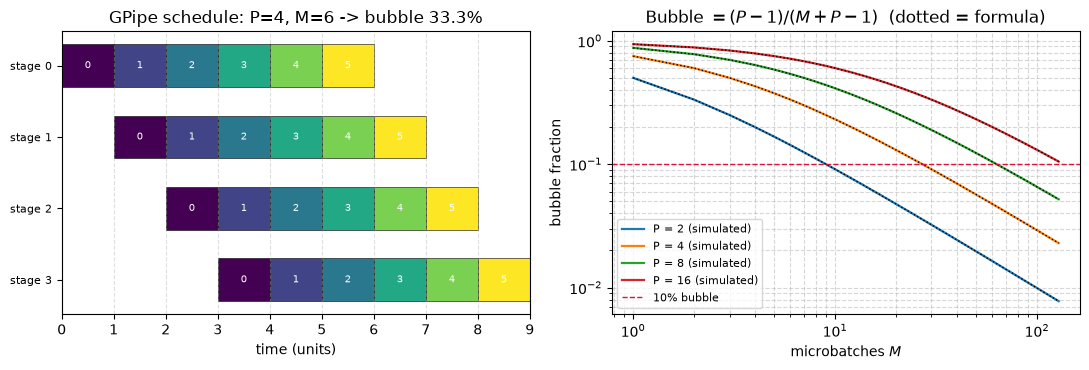

In [13]:
# The schedule, drawn.
Pst, Mmb = 4, 6
mk, bub, fin = simulate_pipeline(Pst, Mmb)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cmap = plt.get_cmap("viridis")
for p in range(Pst):
    for m in range(Mmb):
        start = fin[p, m] - 1.0
        ax[0].barh(p, 1.0, left=start, height=0.6, color=cmap(m / max(Mmb - 1, 1)),
                   edgecolor="k", linewidth=0.4)
        ax[0].text(start + 0.5, p, f"{m}", ha="center", va="center", fontsize=7, color="w")
ax[0].set_yticks(range(Pst)); ax[0].set_yticklabels([f"stage {p}" for p in range(Pst)], fontsize=8)
ax[0].invert_yaxis()
ax[0].set_xlabel("time (units)")
ax[0].set_title(f"GPipe schedule: P={Pst}, M={Mmb} -> bubble {bub:.1%}")
ax[0].set_xlim(0, mk)
ax[0].grid(True, ls="--", alpha=0.4, axis="x")

Ms = np.arange(1, 129)
for Pst2 in [2, 4, 8, 16]:
    sim = [simulate_pipeline(Pst2, int(m))[1] for m in Ms]
    ax[1].loglog(Ms, sim, "-", lw=1.6, label=f"P = {Pst2} (simulated)")
    ax[1].loglog(Ms, (Pst2 - 1) / (Ms + Pst2 - 1), "k:", lw=1.0)
ax[1].axhline(0.1, color="crimson", ls="--", lw=1, label="10% bubble")
ax[1].set_xlabel("microbatches $M$"); ax[1].set_ylabel("bubble fraction")
ax[1].set_title("Bubble $= (P-1)/(M+P-1)$  (dotted = formula)")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5, which="both")
plt.tight_layout()

print(f"{'P':>4}  {'M for bubble < 10%':>19}  {'9(P-1) [algebra]':>17}")
print("-" * 45)
for Pst2 in [2, 4, 8, 16, 32]:
    m_needed = next(m for m in range(1, 100000) if (Pst2 - 1) / (m + Pst2 - 1) < 0.1)
    print(f"{Pst2:>4}  {m_needed:>19}  {9 * (Pst2 - 1):>17}")
print("\nSolve (P-1)/(M+P-1) < 0.1  ->  M > 9(P-1). The microbatch count must scale")
print("with the number of STAGES, and each microbatch must still be big enough to")
print("keep a GPU busy. That product is a lower bound on your global batch size.")

> **Observe:** the simulation reproduces $(P-1)/(M+P-1)$ **exactly** — all 28 tested
> $(P, M)$ pairs agree to machine precision, as they should, because the formula is a
> statement about the schedule and the simulation *is* the schedule. The right-hand plot
> shows the price: to keep the bubble under 10% you need $M > 9(P-1)$ microbatches.
>
> That inequality is the reason pipeline parallelism forces a **large global batch**:
> $B_{\text{global}} = M \times b_{\text{micro}}$, $M$ must scale with the stage count, and
> $b_{\text{micro}}$ must stay big enough that a GPU is not starved. So you cannot pipeline
> deeply *and* train with a small batch size — and Week 7 will show that large batches have their
> own generalization problem. Every axis of parallelism eventually charges you in
> optimization, not just in systems.
>
> Two refinements, for orientation: **1F1B** (PipeDream) reorders the same schedule to
> interleave forward and backward passes, which does **not** change the bubble fraction — it is
> the same $(P-1)/(M+P-1)$ — but it caps the number of in-flight activations at $P$ instead
> of $M$, cutting *memory*. **Interleaved 1F1B** (Megatron) gives each device $v$
> non-contiguous chunks and shrinks the bubble to $\frac{P-1}{vM+P-1}$, at the cost of $v$ times
> as many point-to-point messages. Both change only the schedule: the training loss and
> gradients stay the same.


### The bubble is not the only cost — 1F1B and the memory you forgot

GPipe's schedule has a second bill, and it is the one this week is really about. Run all $M$ forward passes before any backward pass and **all $M$ microbatches' activations are alive at
once**. You shrank the bubble by raising $M$ — but you paid for it in memory, the same resource §5 spends a whole section saving.

**1F1B** (PipeDream) reorders the same units of work: once the pipeline is full, each device does
one backward pass for every forward pass. The bubble is unchanged: it is still $(P-1)/(M+P-1)$, because the dependency graph is the same — but a device holds at most $P$ microbatches
in flight instead of $M$.

```
      microbatches M = 8, stages P = 4;  F = forward, B = backward, number = microbatch, .. = idle

      GPipe
      stage 0  F0 F1 F2 F3 F4 F5 F6 F7 .. .. .. .. .. .. B0 B1 B2 B3 B4 B5 B6 B7
      stage 1  .. F0 F1 F2 F3 F4 F5 F6 F7 .. .. .. .. B0 B1 B2 B3 B4 B5 B6 B7 ..
      stage 2  .. .. F0 F1 F2 F3 F4 F5 F6 F7 .. .. B0 B1 B2 B3 B4 B5 B6 B7 .. ..
      stage 3  .. .. .. F0 F1 F2 F3 F4 F5 F6 F7 B0 B1 B2 B3 B4 B5 B6 B7 .. .. ..

      1F1B
      stage 0  F0 F1 F2 F3 .. .. .. B0 F4 B1 F5 B2 F6 B3 F7 B4 .. B5 .. B6 .. B7
      stage 1  .. F0 F1 F2 .. .. B0 F3 B1 F4 B2 F5 B3 F6 B4 F7 B5 .. B6 .. B7 ..
      stage 2  .. .. F0 F1 .. B0 F2 B1 F3 B2 F4 B3 F5 B4 F6 B5 F7 B6 .. B7 .. ..
      stage 3  .. .. .. F0 B0 F1 B1 F2 B2 F3 B3 F4 B4 F5 B5 F6 B6 F7 B7 .. .. ..
```


In [14]:
def inflight_gpipe(n_stages, n_micro):
    # GPipe: all M forwards, then all M backwards. Stage p holds microbatch m's
    # activations from its forward until its backward. Peak = max over stages.
    peak = 0
    for p in range(n_stages):
        live = 0
        for m in range(n_micro):          # forward phase: nothing is released
            live += 1
            peak = max(peak, live)
    return peak                            # = M, for every stage

def inflight_1f1b(n_stages, n_micro):
    # 1F1B: stage p runs (P-1-p) warmup forwards, then alternates 1F/1B.
    peak = 0
    for p in range(n_stages):
        warm = min(n_stages - 1 - p, n_micro)
        live = 0
        for _ in range(warm):             # warmup forwards
            live += 1
            peak = max(peak, live)
        for _ in range(n_micro - warm):   # steady state: +1 forward, -1 backward
            live += 1
            peak = max(peak, live)
            live -= 1
    return peak                            # = P - p, capped by M


Pst3 = 8
print(f"P = {Pst3} stages, activations of one microbatch = 1 unit")
print(f"{'M':>5}  {'bubble':>8}  {'GPipe peak':>11}  {'1F1B peak':>10}  {'memory saved':>13}")
print("-" * 56)
for Mmb3 in [1, 2, 4, 8, 16, 32, 64, 128]:
    _, bub3, _ = simulate_pipeline(Pst3, Mmb3)
    g = inflight_gpipe(Pst3, Mmb3)
    o = inflight_1f1b(Pst3, Mmb3)
    print(f"{Mmb3:>5}  {bub3:>7.1%}  {g:>11}  {o:>10}  {g / o:>12.1f}x")

print("\nRead the table left to right and the trap is obvious: to push the bubble from")
print("87.5% down to 5% you must raise M from 1 to 128 -- and GPipe's activation memory")
print("goes up by 128x with it. 1F1B caps it at P = 8 and gives up NOTHING on the bubble.")
print("\nThis is why every serious pipeline implementation is 1F1B, and why 'pipeline")
print("parallelism' and 'activation checkpointing' are always discussed together: the")
print("thing that makes pipelining efficient is the thing that makes it run out of memory.")

P = 8 stages, activations of one microbatch = 1 unit
    M    bubble   GPipe peak   1F1B peak   memory saved
--------------------------------------------------------
    1    87.5%            1           1           1.0x
    2    77.8%            2           2           1.0x
    4    63.6%            4           4           1.0x
    8    46.7%            8           8           1.0x
   16    30.4%           16           8           2.0x
   32    17.9%           32           8           4.0x
   64     9.9%           64           8           8.0x
  128     5.2%          128           8          16.0x

Read the table left to right and the trap is obvious: to push the bubble from
87.5% down to 5% you must raise M from 1 to 128 -- and GPipe's activation memory
goes up by 128x with it. 1F1B caps it at P = 8 and gives up NOTHING on the bubble.

This is why every serious pipeline implementation is 1F1B, and why 'pipeline
parallelism' and 'activation checkpointing' are always discussed together

### 🔬 Exercise 2

**Exercise:** the GPipe simulation above assumes every stage costs the same. Real stage
splits are never perfectly balanced — the first stage carries the embedding, the last
carries the LM head and the loss.

1. Extend `simulate_pipeline` to take a per-stage cost vector, and confirm it still
   reproduces $(P-1)/(M+P-1)$ when all costs are equal.
2. Now make one stage 2× slower and measure the bubble. Compare to the balanced case, and
   check the throughput against the claim that a pipeline's rate is set by
   $\max_p \text{cost}_p$ (the **slowest stage**), not by the mean.
3. Given per-layer costs `[1, 1, 3, 1, 1, 1, 1, 1]` and $P = 4$ stages, find the layer→stage
   assignment that minimizes the makespan for $M = 16$. Is it the equal-*layer-count* split?


In [15]:
# --- Reference solution (instructor: blank this out for students) ---

def simulate_pipeline_uneven(costs, n_micro):
    costs = np.asarray(costs, dtype=float)
    n_stages = len(costs)
    finish = np.zeros((n_stages, n_micro))
    for m in range(n_micro):
        for p in range(n_stages):
            dep = finish[p - 1, m] if p > 0 else 0.0
            dev = finish[p, m - 1] if m > 0 else 0.0
            finish[p, m] = max(dep, dev) + costs[p]
    makespan = finish.max()
    busy = n_micro * costs.sum() / n_stages         # mean device busy time
    return makespan, 1.0 - busy / makespan

# (1) equal costs -> recovers the formula
for Pst, Mmb in [(4, 8), (8, 16)]:
    mk, bub = simulate_pipeline_uneven([1.0] * Pst, Mmb)
    print(f"balanced P={Pst}, M={Mmb:>2}: bubble {bub:.6f}  formula {(Pst - 1) / (Mmb + Pst - 1):.6f}")

# (2) one slow stage
print()
Mmb = 16
print("makespan = (time to push microbatch 0 all the way through) + (M-1) x (slowest stage)")
print("         =        sum_p cost_p                             + (M-1) x max_p cost_p\n")
for label, costs in [("balanced      [1,1,1,1]", [1, 1, 1, 1]),
                     ("one 2x stage  [1,2,1,1]", [1, 2, 1, 1]),
                     ("one 3x stage  [1,3,1,1]", [1, 3, 1, 1])]:
    mk, bub = simulate_pipeline_uneven(costs, Mmb)
    pred = sum(costs) + (Mmb - 1) * max(costs)           # fill + steady state at the slow stage
    print(f"{label}  makespan {mk:>5.1f}  bubble {bub:>6.1%}  "
          f"prediction {pred:>5.1f}  {'MATCH' if np.isclose(mk, pred) else 'off'}")
print("\n^ the steady-state rate is set by the SLOWEST stage, so making one stage 3x slower")
print("  makes the WHOLE PIPELINE ~3x slower, and every other device idles 2/3 of the time.")
print("  The mean stage cost is irrelevant. Only the max matters.")

# (3) balance the partition, not the layer count
layer_costs = [1, 1, 3, 1, 1, 1, 1, 1]
Mmb = 16
def split_cost(cuts):
    cuts = [0] + list(cuts) + [len(layer_costs)]
    return [sum(layer_costs[cuts[i]:cuts[i + 1]]) for i in range(len(cuts) - 1)]

import itertools
best = None
for cuts in itertools.combinations(range(1, len(layer_costs)), 3):
    costs = split_cost(cuts)
    if min(costs) == 0:
        continue
    mk, bub = simulate_pipeline_uneven(costs, Mmb)
    if best is None or mk < best[0]:
        best = (mk, cuts, costs, bub)
mk_eq, bub_eq = simulate_pipeline_uneven(split_cost([2, 4, 6]), Mmb)
print(f"\nequal LAYER count [2,2,2,2] -> stage costs {split_cost([2, 4, 6])}  "
      f"makespan {mk_eq:.1f}  bubble {bub_eq:.1%}")
print(f"best balanced split cuts {best[1]}  -> stage costs {best[2]}  "
      f"makespan {best[0]:.1f}  bubble {best[3]:.1%}")
print(f"\nspeedup from balancing COST instead of LAYER COUNT: {mk_eq / best[0]:.2f}x")
print("The expensive layer gets a stage more or less to itself. This is why real")
print("pipeline frameworks profile each layer before they partition it.")

balanced P=4, M= 8: bubble 0.272727  formula 0.272727
balanced P=8, M=16: bubble 0.304348  formula 0.304348

makespan = (time to push microbatch 0 all the way through) + (M-1) x (slowest stage)
         =        sum_p cost_p                             + (M-1) x max_p cost_p

balanced      [1,1,1,1]  makespan  19.0  bubble  15.8%  prediction  19.0  MATCH
one 2x stage  [1,2,1,1]  makespan  35.0  bubble  42.9%  prediction  35.0  MATCH
one 3x stage  [1,3,1,1]  makespan  51.0  bubble  52.9%  prediction  51.0  MATCH

^ the steady-state rate is set by the SLOWEST stage, so making one stage 3x slower
  makes the WHOLE PIPELINE ~3x slower, and every other device idles 2/3 of the time.
  The mean stage cost is irrelevant. Only the max matters.

equal LAYER count [2,2,2,2] -> stage costs [2, 4, 2, 2]  makespan 70.0  bubble 42.9%
best balanced split cuts (2, 3, 5)  -> stage costs [2, 3, 2, 3]  makespan 55.0  bubble 27.3%

speedup from balancing COST instead of LAYER COUNT: 1.27x
The expensive lay

---

## 5. Activation checkpointing: `jax.remat`

Now the other term of $M = 16N + A(B)$. Reverse-mode AD (Week 2) has one structural cost:
the backward pass uses intermediate values from the forward pass, so **the forward pass must keep them
alive**. For an $L$-layer network that means $O(L)$ activations held in memory until the backward pass uses them — and unlike the parameters, this term grows with your
batch size.

Week 4 measured this in passing: `memory_analysis` showed that the gradient needs an order of magnitude more temporary memory than the forward pass. Here is the fix, and it comes at a cost:

> **`jax.remat` (a.k.a. `jax.checkpoint`) throws activations away on the forward pass and
> recomputes them on the backward pass. It buys memory with FLOPs.**

`jax.remat(f)` computes the same function as `f` — `remat(f)(x) == f(x)`, and
`grad(remat(f))(x) == grad(f)(x)` to the last bit. It changes only *what gets stored*. To
see exactly what, we can count the **residuals**: when we linearize the function, the constants captured by the linearized program are exactly the values AD keeps.


In [16]:
def residual_bytes(f, *args):
    # THE honest activation-memory measurement, and it is a count, not an estimate:
    # jax.linearize gives f'(x) as a closure; the constants of ITS jaxpr are exactly
    # the residuals reverse-mode AD must keep alive from forward to backward.
    _, f_lin = jax.linearize(f, *args)
    jaxpr = jax.make_jaxpr(f_lin)(*args)
    total = sum(np.asarray(c).nbytes for c in jaxpr.consts)
    return total, len(jaxpr.consts)


# a deep, narrow stack: exactly the shape where activations dominate
D_S, B_S, L_S = 256, 256, 8
Wstack = jax.random.normal(jax.random.key(0), (L_S, D_S, D_S)) / jnp.sqrt(D_S)
x_s = jax.random.normal(jax.random.key(1), (B_S, D_S))


def stack_plain(Ws, x):
    for i in range(L_S):
        x = jnp.tanh(x @ Ws[i])
    return jnp.sum(x ** 2)

def stack_remat(Ws, x):
    layer = jax.remat(lambda x, w: jnp.tanh(x @ w))
    for i in range(L_S):
        x = layer(x, Ws[i])
    return jnp.sum(x ** 2)


g_plain = jax.jit(jax.grad(stack_plain))(Wstack, x_s)
g_remat = jax.jit(jax.grad(stack_remat))(Wstack, x_s)
print("remat changes the GRADIENT by:", float(jnp.abs(g_plain - g_remat).max()),
      "  <- semantically the identity, as promised\n")

one_act = B_S * D_S * 4          # bytes of ONE (batch, width) activation
print(f"{'':>18}  {'residual arrays':>15}  {'total MB':>9}  {'activations MB':>15}  "
      f"{'in units of 1 act':>18}")
print("-" * 84)
for name, f in [("no remat", stack_plain), ("remat EVERY layer", stack_remat)]:
    tot, n = residual_bytes(f, Wstack, x_s)
    act = tot - Wstack.nbytes                     # the weights are residuals too: x@W's backward needs W
    print(f"{name:>18}  {n:>15}  {tot / 1e6:>9.2f}  {act / 1e6:>15.2f}  {act / one_act:>18.0f}")

print(f"\n(the {Wstack.nbytes / 1e6:.2f} MB of weights are residuals too -- the backward of x@W needs W --")
print(" so subtract them to isolate the ACTIVATION residuals.)")
print(f"\nL = {L_S} layers. No remat keeps ~2L activations. Rematting every layer keeps ~L+1.")
print("That is a factor of 2 -- a CONSTANT. It is still O(L), and O(L) is the problem.")

remat changes the GRADIENT by: 0.0   <- semantically the identity, as promised

                    residual arrays   total MB   activations MB   in units of 1 act
------------------------------------------------------------------------------------
          no remat               26       6.82             4.72                  18


 remat EVERY layer               17       4.46             2.36                   9

(the 2.10 MB of weights are residuals too -- the backward of x@W needs W --
 so subtract them to isolate the ACTIVATION residuals.)

L = 8 layers. No remat keeps ~2L activations. Rematting every layer keeps ~L+1.
That is a factor of 2 -- a CONSTANT. It is still O(L), and O(L) is the problem.


### The first surprise: applying remat to every layer does not change the memory complexity

Look at the last column. Checkpointing *each individual layer* took the activation count
from $\approx 2L$ down to $\approx L+1$ — a **factor of two**, and then it stopped. It is
still $O(L)$, and $O(L)$ is the whole problem: it is what makes a 100-layer network cost
100 activations.

The reason is simple. To rematerialize layer $i$ on the backward pass, you must store its **input**. But layer $i$'s input *is* layer $i-1$'s output — an
activation you were storing anyway. You saved only the intermediates *inside* one
layer, and a single `tanh(x @ W)` has exactly one of those.

**Checkpointing pays off only when you remat groups of layers, not single layers.** Group the
layers into $S$ **segments** and remat a whole segment: now you store $S+1$ boundary
activations instead of $O(L)$, and pay one extra forward pass through each segment.

This is a classic result (Chen et al., 2016; and Griewank's earlier work on
adjoint checkpointing). With $L$ layers in $S$ equal segments:

$$M(S) \;\approx\; \underbrace{S}_{\text{stored boundaries}} \;+\;
\underbrace{\frac{L}{S}}_{\text{live during one segment's recompute}}$$

$$\frac{dM}{dS} = 1 - \frac{L}{S^2} = 0 \;\Longrightarrow\; S^\star = \sqrt{L},
\qquad M(S^\star) = 2\sqrt{L} = O(\sqrt{L})$$

$O(L)$ memory becomes $O(\sqrt{L})$, at the cost of **one extra forward pass** — because every
segment is recomputed exactly once, regardless of $S$. Let us find that $\sqrt{L}$ experimentally.


In [17]:
def bench(f, *args, repeats=5):
    jax.block_until_ready(f(*args))                 # warm up: pay compilation
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        jax.block_until_ready(f(*args))             # dispatch is async -- WAIT
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


def compiled_stats(f, *args):
    c = jax.jit(f).lower(*args).compile()
    m = c.memory_analysis()
    ca = c.cost_analysis()
    ca = ca[0] if isinstance(ca, (list, tuple)) else ca
    return m.temp_size_in_bytes, float(ca.get("flops", np.nan))


# Scan over layers -- Week 4's tool, and the shape every real deep stack has.
D_L, B_L, L_L = 256, 256, 64
Wdeep = jax.random.normal(jax.random.key(0), (L_L, D_L, D_L)) / jnp.sqrt(D_L)
x_deep = jax.random.normal(jax.random.key(1), (B_L, D_L))


def one_layer(carry, w):
    return jnp.tanh(carry @ w), None


def make_stack(S):
    # S = None -> no remat.  Otherwise: S segments of L/S layers, each segment rematted.
    if S is None:
        def f(Ws, x):
            out, _ = jax.lax.scan(one_layer, x, Ws)
            return jnp.sum(out ** 2)
        return f
    per = L_L // S

    def segment(carry, Wseg):
        out, _ = jax.lax.scan(one_layer, carry, Wseg)
        return out, None

    rseg = jax.remat(segment)

    def f(Ws, x):
        out, _ = jax.lax.scan(rseg, x, Ws.reshape(S, per, D_L, D_L))
        return jnp.sum(out ** 2)
    return f


print(f"L = {L_L} layers, width {D_L}, batch {B_L}   |   sqrt(L) = {np.sqrt(L_L):.1f}")
print(f"\n{'segments S':>11}  {'layers/seg':>11}  {'activation MB':>14}  {'compiled GFLOP':>15}  {'grad ms':>9}")
print("-" * 70)
S_grid = [None, 1, 2, 4, 8, 16, 32, 64]
mem_S, flop_S, time_S, labels = [], [], [], []
for S in S_grid:
    f = make_stack(S)
    g = jax.jit(jax.grad(f))
    temp, flops = compiled_stats(jax.grad(f), Wdeep, x_deep)
    t = bench(g, Wdeep, x_deep, repeats=3)
    mem_S.append(temp / 1e6); flop_S.append(flops); time_S.append(t)
    labels.append("none" if S is None else str(S))
    per = "-" if S is None else L_L // S
    print(f"{str(S):>11}  {str(per):>11}  {temp / 1e6:>14.2f}  {flops / 1e9:>15.4f}  {t * 1e3:>9.1f}")

base_mem = mem_S[0]
best_i = 1 + int(np.argmin(mem_S[1:]))
print(f"\nno remat        : {base_mem:>7.2f} MB")
print(f"best (S = {labels[best_i]:>2})    : {mem_S[best_i]:>7.2f} MB   -> {base_mem / mem_S[best_i]:.1f}x less activation memory")
print(f"argmin S = {labels[best_i]}, and sqrt(L) = {np.sqrt(L_L):.1f}, sqrt(2L) = {np.sqrt(2 * L_L):.1f}")
print(f"\nFLOPs: {flop_S[0] / 1e9:.4f} -> {flop_S[1] / 1e9:.4f} GFLOP = "
      f"{flop_S[1] / flop_S[0]:.3f}x, and IDENTICAL for every S.")
print("(XLA counts a loop body once, so read the RATIO, not the absolute GFLOP.)")
print(f"device: {jax.devices()[0].device_kind}")

L = 64 layers, width 256, batch 256   |   sqrt(L) = 8.0

 segments S   layers/seg   activation MB   compiled GFLOP    grad ms
----------------------------------------------------------------------


       None            -           51.38           0.1010       77.0


          1           64           51.38           0.1345       90.9


          2           32           43.52           0.1345       77.0


          4           16           23.07           0.1345       78.0


          8            8           13.63           0.1345       77.5


         16            4           10.49           0.1345       78.5


         32            2           12.06           0.1345       70.5


         64            1           34.60           0.1345       59.8

no remat        :   51.38 MB
best (S = 16)    :   10.49 MB   -> 4.9x less activation memory
argmin S = 16, and sqrt(L) = 8.0, sqrt(2L) = 11.3

FLOPs: 0.1010 -> 0.1345 GFLOP = 1.332x, and IDENTICAL for every S.
(XLA counts a loop body once, so read the RATIO, not the absolute GFLOP.)
device: cpu


theory : memory ~ S + L/S, minimized at S* = sqrt(L) = 8.0
measured: minimum at S = 16, giving 4.9x reduction
theory : reduction ~ 2L / (2 sqrt(L)) = sqrt(L) = 8.0x


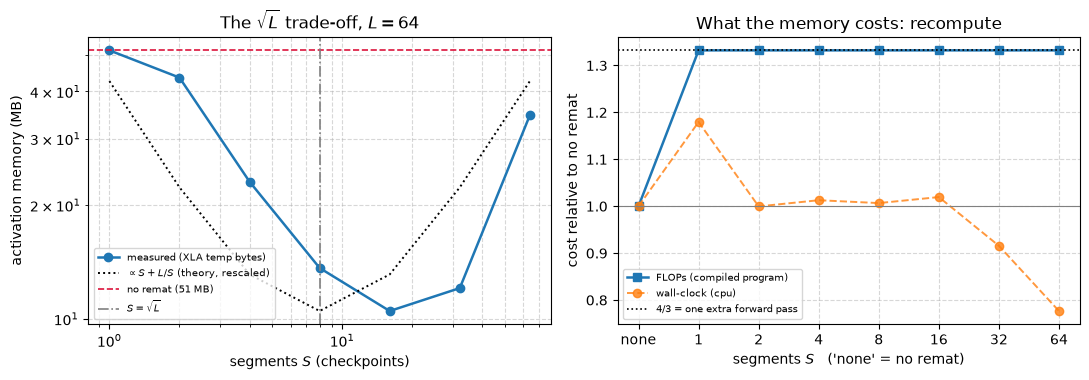

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))

Sv = np.array([1, 2, 4, 8, 16, 32, 64], dtype=float)
meas = np.array(mem_S[1:])
ax[0].loglog(Sv, meas, "o-", lw=1.8, label="measured (XLA temp bytes)")
# the S + L/S model, scaled to the measurement at its own minimum
model = Sv + L_L / Sv
model = model / model.min() * meas.min()
ax[0].loglog(Sv, model, "k:", lw=1.4, label=r"$\propto S + L/S$ (theory, rescaled)")
ax[0].axhline(base_mem, color="crimson", ls="--", lw=1.2, label=f"no remat ({base_mem:.0f} MB)")
ax[0].axvline(np.sqrt(L_L), color="grey", ls="-.", lw=1.2, label=r"$S=\sqrt{L}$")
ax[0].set_xlabel("segments $S$ (checkpoints)")
ax[0].set_ylabel("activation memory (MB)")
ax[0].set_title(f"The $\\sqrt{{L}}$ trade-off, $L = {L_L}$")
ax[0].legend(fontsize=7.5); ax[0].grid(True, ls="--", alpha=0.5, which="both")

ax[1].plot(labels, np.array(flop_S) / flop_S[0], "s-", lw=1.8, label="FLOPs (compiled program)")
ax[1].plot(labels, np.array(time_S) / time_S[0], "o--", lw=1.4, alpha=0.8,
           label=f"wall-clock ({jax.devices()[0].device_kind})")
ax[1].axhline(4 / 3, color="k", ls=":", lw=1.2, label="4/3 = one extra forward pass")
ax[1].axhline(1.0, color="grey", lw=0.8)
ax[1].set_xlabel("segments $S$   ('none' = no remat)")
ax[1].set_ylabel("cost relative to no remat")
ax[1].set_title("What the memory costs: recompute")
ax[1].legend(fontsize=7.5); ax[1].grid(True, ls="--", alpha=0.5)
plt.tight_layout()

print(f"theory : memory ~ S + L/S, minimized at S* = sqrt(L) = {np.sqrt(L_L):.1f}")
print(f"measured: minimum at S = {labels[best_i]}, giving {base_mem / mem_S[best_i]:.1f}x reduction")
print(f"theory : reduction ~ 2L / (2 sqrt(L)) = sqrt(L) = {np.sqrt(L_L):.1f}x")

> **Observe:** the measurement supports the theory, and the key evidence is the **shape** of the curve, not just one point. Activation memory is a
> **U** in $S$: too few segments and recomputing a segment needs a lot of memory (at
> $S = 1$ the memory equals no remat, 51.4 MB); too many and you are storing all the
> boundaries again (at $S = L = 64$ the memory climbs back to 34.6 MB, still below no remat
> because the values inside each layer are recomputed, not stored). The minimum sits in the middle, near where $S + L/S$ predicts, and delivers a **~5× reduction** in activation
> memory. That is the $S + L/S$ trade-off, measured in real bytes.
>
> **Be precise about what was confirmed.** The theory predicts $S^\star = \sqrt{L} = 8$ and
> a $\sqrt{L} = 8\times$ reduction; we measured the argmin one grid point away (at $S=16$,
> on a powers-of-two grid) and a $4.9\times$ reduction. The *shape*, a U with a broad flat bottom over $S \in \{8, 16, 32\}$, is confirmed. The *scaling* with $L$ is not, because we measured only $L = 64$. The constants are not, and we should not expect them to be: $S + L/S$ counts checkpoints, and XLA's buffer assignment also
> holds the loop's carry, the stacked residuals, and whatever its scheduler decides to keep.
> A model that got the constant right by accident would be more suspicious than this one.
>
> And the price is about **4/3**: one extra forward pass, since forward is $\approx 1/3$ of
> forward+backward and every segment is recomputed exactly once — **independent of $S$**.
> That is why the trade is so good: you choose your memory anywhere along the U, and the FLOP cost does not change.
>
> **Read the flat FLOP line as an illustration, not as independent evidence.** XLA's cost
> analysis counts a loop body once, so this `scan`-based count sees one layer whatever the
> value of $S$ (without remat it also gives the same number for $L = 8$ and $L = 64$). The
> 4/3 ratio comes from that one layer, and the independence from $S$ comes from the
> counting argument above, not from this measurement.
>
> **Read the wall-clock line with suspicion.** It is noisy and it does not track the FLOP
> ratio, because XLA:CPU is not memory-constrained and its scheduler makes its own
> decisions about what to keep. On a GPU under real memory pressure the ~33% FLOP overhead
> is what you feel — and you pay it gladly, because the alternative is not a slower program,
> it is no program. This is the trade Week 15 revisits from the other side: when even
> `remat` is not enough to fine-tune a foundation model on a client device, you stop training most of the parameters. That is LoRA, and the PEFT library makes it practical for federated learning.


### Back to the spine: `remat` on the actual Week 3 ResNet

Everything above was a clean stack of dense layers, chosen because it isolates the effect.
Lab 5 is about *our* codebase, so let us apply the same tool to the Equinox ResNet from §1
and check that the story survives contact with `BatchNorm`, convolutions, and a model that
holds non-array leaves.

Equinox gives us `eqx.filter_checkpoint`, which is `jax.remat` that knows how to leave the
static parts of a `Module` alone. The four states stay separate, exactly as they have since
Week 3 — and note which one `remat` interacts with: the **batch statistics** are computed
during the forward pass, so a rematerialized forward computes them a second time. The state
is passed in and returned as a value, so the update itself is applied only once. Equinox's
`BatchNorm` in `mode="batch"` computes the statistics from the batch (it does not read
them), which is why this composes; a layer with a genuine side effect in its forward pass
would not.


In [19]:
def resnet_loss_remat(model, state, x, y):
    # identical to resnet_loss, except each residual block is checkpointed
    def forward_one(m, s, xi):
        h, s = m.stem_bn(m.stem(xi), s)
        h = jax.nn.relu(h)
        for blk in m.blocks:
            h, s = eqx.filter_checkpoint(lambda b, hh, ss: b(hh, ss))(blk, h, s)
        h = jnp.mean(h, axis=(1, 2))
        return m.head(h), s

    logits, state = eqx.filter_vmap(forward_one, in_axes=(None, None, 0),
                                    out_axes=(0, None), axis_name="batch")(model, state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state


xb, yb = X_tr[:32], Y_tr[:32]     # a small batch: this cell traces a 16-block model 8 times

# remat is a DEPTH technique, so sweep the depth -- 2 blocks is the Week 3 model.
print(f"{'blocks':>7}  {'activations MB, plain':>21}  {'+ checkpoint':>13}  {'saved':>7}  "
      f"{'FLOPs':>7}  {'XLA:CPU temp MB':>16}")
print("-" * 82)
depth_rows = []
for n_blk in [2, 4, 8, 16]:
    m_d, bn_d = eqx.nn.make_with_state(ResNet)(jax.random.key(1), n_blocks=n_blk)
    p_d, st_d = eqx.partition(m_d, eqx.is_inexact_array)
    p_bytes = sum(np.asarray(l).nbytes for l in jax.tree.leaves(p_d))

    row = []
    for lf in [resnet_loss, resnet_loss_remat]:
        f = lambda p: lf(eqx.combine(p, st_d), bn_d, xb, yb)[0]
        tot, _ = residual_bytes(f, p_d)
        temp, flops = compiled_stats(jax.grad(f), p_d)
        row.append(((tot - p_bytes) / 1e6, flops, temp / 1e6))
    depth_rows.append((n_blk, row))
    print(f"{n_blk:>7}  {row[0][0]:>21.2f}  {row[1][0]:>13.2f}  {row[0][0] / row[1][0]:>6.2f}x  "
          f"{row[1][1] / row[0][1]:>6.3f}x  {row[0][2]:>7.1f} -> {row[1][2]:>5.1f}")

# correctness, on the Week 3 model
f0 = lambda p: resnet_loss(eqx.combine(p, static0), bn0, xb, yb)[0]
f1 = lambda p: resnet_loss_remat(eqx.combine(p, static0), bn0, xb, yb)[0]
g0, g1 = jax.jit(jax.grad(f0))(params0), jax.jit(jax.grad(f1))(params0)
gmax = max(float(jnp.abs(a - b).max()) for a, b in zip(jax.tree.leaves(g0), jax.tree.leaves(g1)))
print(f"\nloss plain {float(jax.jit(f0)(params0)):.8f}  remat {float(jax.jit(f1)(params0)):.8f}")
print(f"max |gradient difference| over the whole PyTree: {gmax:.2e}   <- identical, as promised")

print(f"\nThe saving GROWS with depth: {depth_rows[0][1][0][0] / depth_rows[0][1][1][0]:.1f}x at "
      f"{depth_rows[0][0]} blocks -> {depth_rows[-1][1][0][0] / depth_rows[-1][1][1][0]:.1f}x at "
      f"{depth_rows[-1][0]} blocks. That is the whole point: remat is a")
print("DEPTH technique, and Week 3's 2-block model is the least impressive case there is.")
print("\nNOW LOOK AT THE LAST COLUMN, because it disagrees with everything else.")

 blocks  activations MB, plain   + checkpoint    saved    FLOPs   XLA:CPU temp MB
----------------------------------------------------------------------------------


      2                  16.26           4.20    3.87x   1.179x     12.1 ->  12.1


      4                  29.36           5.24    5.60x   1.177x     20.5 ->  21.6


      8                  55.58           7.34    7.57x   1.173x     37.4 ->  40.5


     16                 108.01          11.54    9.36x   1.166x     71.1 ->  78.4



loss plain 1.36534333  remat 1.36534333
max |gradient difference| over the whole PyTree: 0.00e+00   <- identical, as promised

The saving GROWS with depth: 3.9x at 2 blocks -> 9.4x at 16 blocks. That is the whole point: remat is a
DEPTH technique, and Week 3's 2-block model is the least impressive case there is.

NOW LOOK AT THE LAST COLUMN, because it disagrees with everything else.


> **Observe:** two things happened, and the second one is more instructive than the first.
>
> **The trade holds on the real codebase.** Residual activations fall by ~4× at 2 blocks and
> ~9× at 16, for ~1.2× the FLOPs, with gradients **identical across the entire PyTree**. And the saving *grows with depth*, which is why Week 3's 2-block model is the least impressive case you will ever apply this to.
>
> **This is not the $O(\sqrt{L})$ result.** We checkpoint every block, so both columns are still
> $O(L)$. They fit straight lines: about 6.55 MB and 0.52 MB per block, on top of a shared
> 3.15 MB. The ratio grows only because the fixed part matters less at depth, and extrapolating
> those lines, it levels off near 12.5×.
>
> Note also what did **not** have to change: `eqx.partition`/`combine`, the separation of
> parameters from batch statistics, the PRNG threading. `remat` is a transformation, and it
> composes with a codebase that kept its state explicit — the third time that Week 3
> decision has paid for itself, and the same reason Week 8 can hand this model to Flower.
>
> **And XLA:CPU's `temp` bytes contradict it** — they stay flat at 2 blocks and go *up* beyond that.
> This does not mean `remat` is broken: the gradients are identical and the stored residuals
> fall. The likely cause is the CPU backend, which is not memory-constrained and assigns buffers
> on its own, but we have not diagnosed it. The compiler has not simply folded the recompute away,
> because the FLOP ratio stays near 1.17×. Two honest measurements disagree, so you have to say **which one answers the
> question**. The question is *"how many activations does reverse-mode AD have to keep
> alive?"* — that is a property of the program, and `residual_bytes` counts it exactly.
> It does not count the temporary memory used while a block is recomputed, so 9.4× is a saving
> in stored values, not in peak memory. The
> compiler's `temp` is a property of a particular backend's scheduler on a machine with no
> memory pressure, so it does not answer this question.
>
> This also qualifies the U-curve above, which was measured with `temp`. Treat that curve as
> evidence about this compiler on this machine until the GPU node confirms it.
>
> That is why §8's memory numbers come from a program-level measurement and why Further
> Exercise 1 is not optional: on the GPU node, `memory_stats()` is the arbiter, and finding
> out which of these two columns it agrees with is worth more than either column.


### Checkpoint policies: you do not have to choose all-or-nothing

`jax.remat`'s default policy is "save nothing, recompute everything". That is one end of a
spectrum. `jax.checkpoint_policies` lets you name what is *worth* keeping — and there is an
obvious candidate.

The rule of thumb: **save the outputs of expensive ops, recompute the cheap ones.** A matmul
costs $O(Bd^2)$ FLOPs; a `gelu` or a `tanh` costs $O(Bd)$ and is memory-bound. So keeping
the matmul outputs and recomputing every elementwise op should give a large part of the
memory saving for nearly none of the recompute. `dots_saveable` does exactly that. Let us
see whether the rule of thumb survives a measurement — and where each policy actually lands
on the memory/FLOPs frontier.


In [20]:
# a transformer-shaped block stack: d -> 4d -> d, which is where the activations live
D_P, B_P, L_P = 256, 128, 24
kA2, kB2, kx2 = jax.random.split(jax.random.key(5), 3)
Astk = jax.random.normal(kA2, (L_P, D_P, 4 * D_P)) / jnp.sqrt(D_P)
Bstk = jax.random.normal(kB2, (L_P, 4 * D_P, D_P)) / jnp.sqrt(4 * D_P)
x_p = jax.random.normal(kx2, (B_P, D_P))


def mlp_block(carry, ws):
    a, b = ws
    return carry + jax.nn.gelu(carry @ a) @ b, None      # residual + MLP: the standard block


def make_policy_stack(body):
    def f(A, B, x):
        out, _ = jax.lax.scan(body, x, (A, B))
        return jnp.sum(out ** 2)
    return f


cp = jax.checkpoint_policies
variants = [
    ("no remat", mlp_block),
    ("remat, everything_saveable", jax.remat(mlp_block, policy=cp.everything_saveable)),
    ("remat, dots_saveable", jax.remat(mlp_block, policy=cp.dots_saveable)),
    ("remat, nothing_saveable (default)", jax.remat(mlp_block)),
]

print(f"{'policy':>34}  {'activation MB':>14}  {'FLOPs':>8}  {'ms':>7}")
print("-" * 70)
pol_names, pol_mem, pol_flop = [], [], []
for name, body in variants:
    f = make_policy_stack(body)
    g = jax.jit(jax.grad(f, argnums=(0, 1)))
    temp, flops = compiled_stats(jax.grad(f, argnums=(0, 1)), Astk, Bstk, x_p)
    t = bench(g, Astk, Bstk, x_p, repeats=3)
    pol_names.append(name.replace("remat, ", "")); pol_mem.append(temp / 1e6); pol_flop.append(flops)
    print(f"{name:>34}  {temp / 1e6:>14.2f}  {flops / 1e9:>8.4f}  {t * 1e3:>7.1f}")

base_m, base_f = pol_mem[0], pol_flop[0]
print()
for n, m, fl in zip(pol_names, pol_mem, pol_flop):
    print(f"{n:>26}  memory {base_m / m:>5.1f}x smaller   FLOPs {fl / base_f:>5.3f}x more")
print("\n'everything_saveable' == no remat (it saves everything, so nothing is recomputed):")
print("a useful sanity check that the policy knob is doing what it says.")

                            policy   activation MB     FLOPs       ms
----------------------------------------------------------------------


                          no remat           82.05    0.4059     68.0


        remat, everything_saveable           82.05    0.4083     92.1


              remat, dots_saveable           19.66    0.4072     73.2


 remat, nothing_saveable (default)            6.68    0.4741     91.2

                  no remat  memory   1.0x smaller   FLOPs 1.000x more
       everything_saveable  memory   1.0x smaller   FLOPs 1.006x more
             dots_saveable  memory   4.2x smaller   FLOPs 1.003x more
nothing_saveable (default)  memory  12.3x smaller   FLOPs 1.168x more

'everything_saveable' == no remat (it saves everything, so nothing is recomputed):
a useful sanity check that the policy knob is doing what it says.


dots_saveable      : 4.2x less memory for +0.3% FLOPs
nothing_saveable   : 12.3x less memory for +16.8% FLOPs

In this measurement the rule of thumb holds: saving the matmul outputs and
recomputing every elementwise op adds under 2% FLOPs and saves over 2x memory.
Full remat saves more memory and costs more FLOPs, so choose by what you are short of.
Memory here is XLA:CPU temp and FLOPs count each scan body once: confirm on the GPU node.


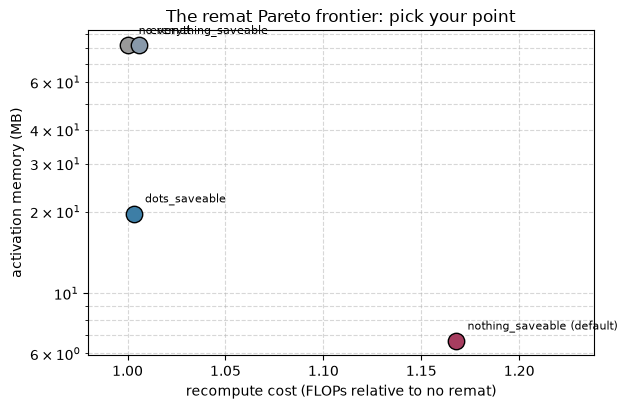

In [21]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
colors = ["#999999", "#8899aa", "#3d7ea6", "#a63d5f"]
for i, (n, m, fl) in enumerate(zip(pol_names, pol_mem, pol_flop)):
    ax.scatter(fl / base_f, m, s=140, color=colors[i], edgecolor="k", zorder=3, label=n)
    ax.annotate(n, (fl / base_f, m), textcoords="offset points", xytext=(8, 8), fontsize=8)
ax.set_xlabel("recompute cost (FLOPs relative to no remat)")
ax.set_ylabel("activation memory (MB)")
ax.set_yscale("log")
ax.set_title("The remat Pareto frontier: pick your point")
ax.grid(True, ls="--", alpha=0.5, which="both")
ax.set_xlim(0.98, max(np.array(pol_flop) / base_f) * 1.06)
plt.tight_layout()

i_dots = pol_names.index("dots_saveable")
i_none = pol_names.index("nothing_saveable (default)")
print(f"dots_saveable      : {base_m / pol_mem[i_dots]:.1f}x less memory for "
      f"{100 * (pol_flop[i_dots] / base_f - 1):+.1f}% FLOPs")
print(f"nothing_saveable   : {base_m / pol_mem[i_none]:.1f}x less memory for "
      f"{100 * (pol_flop[i_none] / base_f - 1):+.1f}% FLOPs")
# check the rule against the numbers instead of printing a fixed verdict
rule_holds = (pol_flop[i_dots] / base_f < 1.02) and (base_m / pol_mem[i_dots] > 2.0)
if rule_holds:
    print("\nIn this measurement the rule of thumb holds: saving the matmul outputs and")
    print("recomputing every elementwise op adds under 2% FLOPs and saves over 2x memory.")
else:
    print("\nIn this measurement the rule of thumb does NOT hold (under 2% FLOPs, over 2x memory).")
print("Full remat saves more memory and costs more FLOPs, so choose by what you are short of.")
print("Memory here is XLA:CPU temp and FLOPs count each scan body once: confirm on the GPU node.")

### 🔬 Exercise 3

**Exercise:** `remat`'s job is to make an impossible batch possible. Quantify that.

For the §5 MLP stack, sweep the batch size $B \in \{32, 64, \dots, 1024\}$ and measure
activation memory with and without `remat`. Then:

1. Fit/confirm that activation memory is **linear in $B$** in both cases, and extract the
   two slopes (MB per example).
2. Given a per-device activation budget of **64 MB**, report the **maximum feasible batch**
   for each, and the ratio.
3. State the throughput consequence honestly: `remat` costs roughly 17–33% more FLOPs *per example*.
   If it lets you fit 8× the batch, is that a win? (Careful — think about what the batch is
   *for*.)


  batch   no remat (MB)   remat (MB)    ratio
----------------------------------------------


     32           22.09         3.24     6.8x


     64           42.07         4.39     9.6x


    128           82.05         6.68    12.3x


    256          162.01        11.01    14.7x


    512          321.91        20.97    15.3x


   1024          641.73        40.89    15.7x

linear fit  no remat:  624.64 KB/example   R^2 = 1.00000
linear fit  remat   :   38.00 KB/example   R^2 = 0.99957
^ activation memory is LINEAR in the batch, as the model says it must be.

at a 64 MB activation budget:
   no remat -> max batch ~     99
   remat    -> max batch ~  1,638   (16.5x larger)
   (extrapolated: the largest batch we measured is 1024)
   Memory here is XLA:CPU temp: confirm these numbers on the GPU node.

(3) Is it a win? It depends what you wanted the batch FOR.
   - To fit a model that OOMs at any batch: unambiguously yes -- ~17-33% more FLOPs
     beats not running at all.
   - For throughput on a fixed model: a bigger batch amortizes the weight reads,
     so examples/sec often IMPROVES despite the extra FLOPs -- measure it.
   - For a bigger EFFECTIVE batch: gradient accumulation gets you the same
     statistics at no FLOP overhead. Prefer it when memory is the only issue.
   - And a bigger batch is not automa

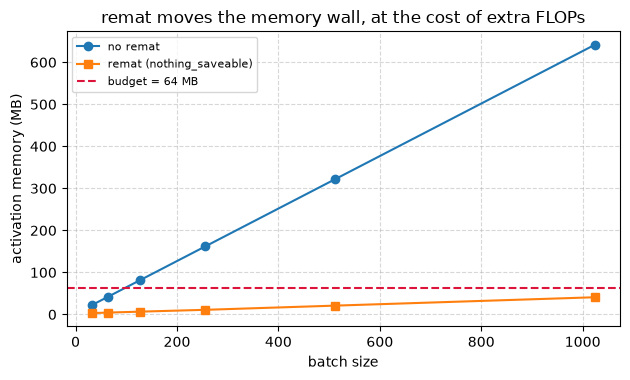

In [22]:
# --- Reference solution (instructor: blank this out for students) ---

BUDGET_MB = 64.0
batch_grid = [32, 64, 128, 256, 512, 1024]
mem_plain, mem_remat = [], []

print(f"{'batch':>7}  {'no remat (MB)':>14}  {'remat (MB)':>11}  {'ratio':>7}")
print("-" * 46)
for b in batch_grid:
    xb = jax.random.normal(jax.random.key(9), (b, D_P))
    m0, _ = compiled_stats(jax.grad(make_policy_stack(mlp_block), argnums=(0, 1)), Astk, Bstk, xb)
    m1, _ = compiled_stats(jax.grad(make_policy_stack(jax.remat(mlp_block)), argnums=(0, 1)),
                           Astk, Bstk, xb)
    mem_plain.append(m0 / 1e6); mem_remat.append(m1 / 1e6)
    print(f"{b:>7}  {m0 / 1e6:>14.2f}  {m1 / 1e6:>11.2f}  {m0 / max(m1, 1e-9):>6.1f}x")

# (1) linearity: memory should be a straight line in the batch size
sl_plain, ic_plain = np.polyfit(batch_grid, mem_plain, 1)
sl_remat, ic_remat = np.polyfit(batch_grid, mem_remat, 1)
r2 = lambda x, y: 1 - np.sum((np.polyval(np.polyfit(x, y, 1), x) - y) ** 2) / np.sum((y - np.mean(y)) ** 2)
print(f"\nlinear fit  no remat: {sl_plain * 1e3:>7.2f} KB/example   R^2 = {r2(batch_grid, mem_plain):.5f}")
print(f"linear fit  remat   : {sl_remat * 1e3:>7.2f} KB/example   R^2 = {r2(batch_grid, mem_remat):.5f}")
print("^ activation memory is LINEAR in the batch, as the model says it must be.")

# (2) max feasible batch under the budget (the fit has a fixed part, so keep the intercept)
b_plain = (BUDGET_MB - ic_plain) / sl_plain
b_remat = (BUDGET_MB - ic_remat) / sl_remat
print(f"\nat a {BUDGET_MB:.0f} MB activation budget:")
print(f"   no remat -> max batch ~{b_plain:>7,.0f}")
print(f"   remat    -> max batch ~{b_remat:>7,.0f}   ({b_remat / b_plain:.1f}x larger)")
if max(b_plain, b_remat) > max(batch_grid):
    print(f"   (extrapolated: the largest batch we measured is {max(batch_grid)})")
print("   Memory here is XLA:CPU temp: confirm these numbers on the GPU node.")

plt.figure(figsize=(6.4, 3.9))
plt.plot(batch_grid, mem_plain, "o-", label="no remat")
plt.plot(batch_grid, mem_remat, "s-", label="remat (nothing_saveable)")
plt.axhline(BUDGET_MB, color="crimson", ls="--", label=f"budget = {BUDGET_MB:.0f} MB")
plt.xlabel("batch size"); plt.ylabel("activation memory (MB)")
plt.title("remat moves the memory wall, at the cost of extra FLOPs")
plt.legend(fontsize=8); plt.grid(True, ls="--", alpha=0.5); plt.tight_layout()

print("\n(3) Is it a win? It depends what you wanted the batch FOR.")
print("   - To fit a model that OOMs at any batch: unambiguously yes -- ~17-33% more FLOPs")
print("     beats not running at all.")
print("   - For throughput on a fixed model: a bigger batch amortizes the weight reads,")
print("     so examples/sec often IMPROVES despite the extra FLOPs -- measure it.")
print("   - For a bigger EFFECTIVE batch: gradient accumulation gets you the same")
print("     statistics at no FLOP overhead. Prefer it when memory is the only issue.")
print("   - And a bigger batch is not automatically better OPTIMIZATION -- Week 7's")
print("     large-batch generalization gap is exactly this bill arriving.")

---

## 6. Mixed precision: half the bytes, most of the time

Activations do not need 32 bits. The gradient of a `gelu` does not care about the 24th
significant bit, and the matmul units on modern accelerators are often faster in 16-bit. Halving the activation dtype halves $A(B)$ and roughly
halves the wire traffic of every collective in §2–§3.

Two 16-bit formats, and the choice is not close:

| | float32 | float16 | **bfloat16** |
|---|---|---|---|
| exponent / mantissa bits | 8 / 23 | 5 / 10 | **8 / 7** |
| dynamic range | $\sim 10^{\pm 38}$ | $\sim 10^{\pm 5}$ | $\sim 10^{\pm 38}$ (**same as f32**) |
| machine epsilon | $1.2\times10^{-7}$ | $9.8\times10^{-4}$ | $7.8\times10^{-3}$ |
| overflows/underflows on real gradients? | rarely | **yes** — needs loss scaling | rarely |

`float16` has a *bigger mantissa* than `bfloat16` and is still the worse choice for
training, because its five exponent bits cannot represent a small gradient — hence the whole
apparatus of dynamic loss scaling. `bfloat16` is float32 with the mantissa chopped off: same
range, no loss scaling, and you trade precision, which is the thing you can afford to trade.

But you cannot trade it *everywhere*. Here is what goes wrong.


In [23]:
for dt in [jnp.float32, jnp.float16, jnp.bfloat16]:
    fi = jnp.finfo(dt)
    print(f"{np.dtype(dt).name:>10}  bits {fi.bits:>2}  eps {float(fi.eps):>10.3e}  "
          f"max {float(fi.max):>10.3e}  tiny {float(fi.tiny):>10.3e}")

print("\n--- the parameter-update problem ---")
lr_g = 3e-4          # a perfectly ordinary  learning_rate * gradient  product
w32 = jnp.float32(1.0)
w16 = jnp.bfloat16(1.0)
print(f"a typical update: -{lr_g}")
print(f"   float32 : 1.0 - {lr_g} = {float(w32 - jnp.float32(lr_g)):.8f}   moved: "
      f"{float(w32 - jnp.float32(lr_g)) != 1.0}")
print(f"   bfloat16: 1.0 - {lr_g} = {float(w16 - jnp.bfloat16(lr_g)):.8f}   moved: "
      f"{float(w16 - jnp.bfloat16(lr_g)) != 1.0}")
print(f"\n   bfloat16 eps = {float(jnp.finfo(jnp.bfloat16).eps):.4f}. Any update smaller than "
      f"~eps*|w| ROUNDS AWAY.")

print("\n--- 1000 steps of that update ---")
a = jnp.bfloat16(1.0)
for _ in range(1000):
    a = (a - jnp.bfloat16(lr_g)).astype(jnp.bfloat16)      # pure bf16 parameter
m = jnp.float32(1.0)
for _ in range(1000):
    m = m - jnp.float32(lr_g)                              # fp32 MASTER weight
print(f"   pure bfloat16 parameter after 1000 steps : {float(a):.6f}")
print(f"   fp32 master weight after 1000 steps      : {float(m):.6f}")
print(f"   exact answer                             : {1.0 - 1000 * lr_g:.6f}")
print("\n   The bfloat16 parameter NEVER MOVED. Not slowly -- not at all. Every single")
print("   update was rounded away, and nothing raised, and the loss curve would be flat")
print("   while the code looked perfect.")

   float32  bits 32  eps  1.192e-07  max  3.403e+38  tiny  1.175e-38
   float16  bits 16  eps  9.766e-04  max  6.550e+04  tiny  6.104e-05
  bfloat16  bits 16  eps  7.812e-03  max  3.390e+38  tiny  1.175e-38

--- the parameter-update problem ---
a typical update: -0.0003
   float32 : 1.0 - 0.0003 = 0.99970001   moved: True
   bfloat16: 1.0 - 0.0003 = 1.00000000   moved: False

   bfloat16 eps = 0.0078. Any update smaller than ~eps*|w| ROUNDS AWAY.

--- 1000 steps of that update ---


   pure bfloat16 parameter after 1000 steps : 1.000000
   fp32 master weight after 1000 steps      : 0.700010
   exact answer                             : 0.700000

   The bfloat16 parameter NEVER MOVED. Not slowly -- not at all. Every single
   update was rounded away, and nothing raised, and the loss curve would be flat
   while the code looked perfect.


### The standard recipe

That is why "mixed" precision is mixed. The rule follows directly from the experiment
above: **anything that accumulates many small contributions stays in float32; everything
else can be bfloat16.**

| tensor | dtype | why |
|--------|-------|-----|
| master parameters $\theta$ | **float32** | many tiny updates accumulate — the cell above |
| Adam moments $m, v$ | **float32** | same: running averages of small numbers |
| compute-cast weights | bfloat16 | consumed once per step by the matmul |
| **activations** | **bfloat16** | the term we are attacking; dominates $A(B)$ |
| **gradients on the wire** | bfloat16 | halves every collective in §2–§3 |
| loss / softmax / layernorm reductions | float32 | sums over the batch or the width accumulate |

Note the accounting consequence, which surprises people: mixed precision does **not**
reduce the $16N$ persistent term — it *adds* to it, because you keep the fp32 master plus a
bf16 copy. It attacks $A(B)$, the activations. Combined with §7's ZeRO it becomes the
familiar "$2 + 2 + 12$ bytes per parameter" of the ZeRO paper.


In [24]:
def cast_args(dtype):
    return Astk.astype(dtype), Bstk.astype(dtype), x_p.astype(dtype)


def make_prec_stack(body):
    def f(A, B, x):
        out, _ = jax.lax.scan(body, x, (A, B))
        return jnp.sum(out.astype(jnp.float32) ** 2)     # reduce in fp32, ALWAYS
    return f


# We measure with residual_bytes here, NOT with the compiler's temp bytes. Reason, stated
# plainly: XLA:CPU has no bfloat16 arithmetic, so it upcasts every bf16 matmul to fp32 and
# materialises fp32 buffers -- the CPU's temp bytes for bf16 come out LARGER, which is an
# artefact of this backend, not a fact about mixed precision. The residual count is the
# dtype-honest measurement: it counts the arrays AD keeps, at their actual element size.
print(f"{'dtype':>10}  {'weights MB':>11}  {'activations MB':>15}  {'total residual MB':>18}  {'vs fp32':>8}")
print("-" * 72)
mp_rows = []
for dt in [jnp.float32, jnp.bfloat16]:
    args = cast_args(dt)
    tot, _ = residual_bytes(make_prec_stack(mlp_block), *args)
    wts = args[0].nbytes + args[1].nbytes
    act = tot - wts
    mp_rows.append(act / 1e6)
    print(f"{np.dtype(dt).name:>10}  {wts / 1e6:>11.2f}  {act / 1e6:>15.2f}  {tot / 1e6:>18.2f}  "
          f"{mp_rows[0] / (act / 1e6):>7.2f}x")

print(f"\nbfloat16 activations: {mp_rows[0] / mp_rows[1]:.2f}x less activation memory.")
print("2.00x is the ceiling and we are exactly at it -- this is bytes per element, and there")
print("is no cleverness involved. Which is exactly why it is the FIRST thing to try.")

# and it composes with remat, multiplicatively
args_bf = cast_args(jnp.bfloat16)
tot_rb, _ = residual_bytes(make_prec_stack(jax.remat(mlp_block)), *args_bf)
act_rb = (tot_rb - args_bf[0].nbytes - args_bf[1].nbytes) / 1e6
tot_r32, _ = residual_bytes(make_prec_stack(jax.remat(mlp_block)), *cast_args(jnp.float32))
act_r32 = (tot_r32 - Astk.nbytes - Bstk.nbytes) / 1e6
print(f"\n{'configuration':>26}  {'activations MB':>15}  {'vs fp32, no remat':>18}")
print("-" * 64)
for name, v in [("fp32, no remat", mp_rows[0]), ("bfloat16, no remat", mp_rows[1]),
                ("fp32 + remat", act_r32), ("bfloat16 + remat", act_rb)]:
    print(f"{name:>26}  {v:>15.2f}  {mp_rows[0] / v:>17.1f}x")
print(f"\n{mp_rows[0] / mp_rows[1]:.1f}x (dtype) x {mp_rows[0] / act_r32:.1f}x (remat) = "
      f"{(mp_rows[0] / mp_rows[1]) * (mp_rows[0] / act_r32):.1f}x predicted, "
      f"{mp_rows[0] / act_rb:.1f}x measured together.")
print("The two techniques are ORTHOGONAL -- one changes bytes-per-element, the other")
print("changes how-many-elements -- so their savings MULTIPLY. Stack them.")
print()
print(f"On TIME, this notebook has nothing honest to say: {jax.devices()[0].device_kind} has no bf16")
print("matmul units, so it emulates them and bf16 is SLOWER here. On an A100/H100 the bf16")
print("matmul is several times faster and mixed precision is a throughput win as well as a")
print("memory win. That asymmetry is precisely why a performance claim must name the device.")

     dtype   weights MB   activations MB   total residual MB   vs fp32
------------------------------------------------------------------------


   float32        50.33            78.77              129.11     1.00x


  bfloat16        25.17            39.45               64.62     2.00x

bfloat16 activations: 2.00x less activation memory.
2.00x is the ceiling and we are exactly at it -- this is bytes per element, and there
is no cleverness involved. Which is exactly why it is the FIRST thing to try.

             configuration   activations MB   vs fp32, no remat
----------------------------------------------------------------
            fp32, no remat            78.77                1.0x
        bfloat16, no remat            39.45                2.0x
              fp32 + remat             3.28               24.0x
          bfloat16 + remat             1.70               46.2x

2.0x (dtype) x 24.0x (remat) = 48.0x predicted, 46.2x measured together.
The two techniques are ORTHOGONAL -- one changes bytes-per-element, the other
changes how-many-elements -- so their savings MULTIPLY. Stack them.

On TIME, this notebook has nothing honest to say: cpu has no bf16
matmul units, so it emulates them and b

> **Observe:** `bfloat16` halves the activation memory exactly, because that is arithmetic,
> and it composes multiplicatively with `remat` because the two attack different factors of
> the same product. The 24× and 46× figures count stored residuals only: they leave out the
> temporary memory used during recompute, so the saving in peak memory is smaller. But the pure-`bfloat16` parameter that never moved is the cell to
> remember: mixed precision is not a dtype you set globally, it is a **decision per tensor**,
> and the tensors that accumulate keep their bits. Getting it wrong does not crash — it
> gives you a flat loss curve and a week of debugging the wrong thing.
>
> This comes back in Week 10, from the other end. There the question is "how few bits can a
> **gradient** survive on the wire?", the answer is 8 or fewer with **error feedback**
> (accumulate the quantization residual locally and add it to the next update) — and error
> feedback exists for exactly the reason the bf16 parameter above stopped moving. Same
> failure, a related fix, different link.


---

## 7. ZeRO: stop keeping copies nobody needs

Back to the $16N$ term. Under data parallelism, all $P$ devices hold identical copies of
$\theta$, $g$, $m$, $v$. Every device computes the *same* Adam update and gets the *same*
answer. So both the work and the memory are repeated $P$ times.

ZeRO (Rajbhandari et al., 2020) removes this repetition, and its first two stages add **no
extra communication**. Device $i$ owns shard $i$ of the parameters, updates only that shard,
and shares the result. There are three stages, and each one shards more than the last:

| stage | shard | bytes/param/device (fp32 + Adam) | extra comm vs plain DP |
|-------|-------|------------------------------------|------------------------|
| plain DP | nothing | $4 + 4 + 8 = 16$ | AllReduce($g$) |
| **ZeRO-1** | optimizer state $m, v$ | $4 + 4 + 8/P$ | **none** — AllReduce already splits into ReduceScatter + AllGather |
| **ZeRO-2** | + gradients $g$ | $4 + 4/P + 8/P$ | **none** |
| **ZeRO-3** (FSDP) | + parameters $\theta$ | $(4 + 4 + 8)/P = 16/P$ | **+1 AllGather of $\theta$ per layer, per pass** |

Stages 1 and 2 save memory at no communication cost, which is rare in systems work. The
reason comes from Week 5: a ring **AllReduce is already implemented as ReduceScatter followed
by AllGather**. After the ReduceScatter, device $i$ already holds the fully reduced shard $i$
of the gradient. So it can update that shard right away, then AllGather the *updated
parameters* instead of the gradients. The bytes and the messages stay the same, and the
optimizer memory becomes $P$ times smaller.

ZeRO-3 is where the cost starts. The parameters themselves are sharded, so each layer must be
gathered just before it is used and dropped just after. This is real extra traffic. It can
overlap with compute, though, which is why FSDP is still widely used for large models.


In [25]:
N_Z = 1_048_576                                     # 1M-parameter toy model, flat
mesh_z = jax.make_mesh((8, ), ("zero",))
Pz = mesh_z.shape["zero"]

params_z = {"w": jax.random.normal(jax.random.key(0), (N_Z,)) * 0.02}
opt_z = optax.adamw(1e-3)
state_z = opt_z.init(params_z)

rep_z = NamedSharding(mesh_z, P())
shd_z = NamedSharding(mesh_z, P("zero"))
put_tree = lambda t, s: jax.tree.map(
    lambda a: jax.device_put(a, s if (hasattr(a, "ndim") and a.ndim >= 1) else rep_z), t)

grads_z = jax.tree.map(lambda a: jnp.ones_like(a) * 1e-3, params_z)


def adam_update(p, s, g):
    u, s = opt_z.update(g, s, p)
    return optax.apply_updates(p, u), s


print(f"{'configuration':>28}  {'params':>8}  {'grads':>8}  {'m, v':>8}  {'args MB/device':>15}")
print("-" * 76)
rows_z = []
for name, sp, sg, ss in [("plain DP (all replicated)", rep_z, rep_z, rep_z),
                         ("ZeRO-1 (shard m, v)", rep_z, rep_z, shd_z),
                         ("ZeRO-2 (+ shard g)", rep_z, shd_z, shd_z),
                         ("ZeRO-3 (+ shard theta)", shd_z, shd_z, shd_z)]:
    pz, gz, sz = put_tree(params_z, sp), put_tree(grads_z, sg), put_tree(state_z, ss)
    c = jax.jit(adam_update).lower(pz, sz, gz).compile()
    mb = c.memory_analysis().argument_size_in_bytes / 1e6
    rows_z.append((name, mb))
    tag = lambda s: "shard" if s is shd_z else "full"
    print(f"{name:>28}  {tag(sp):>8}  {tag(sg):>8}  {tag(ss):>8}  {mb:>15.3f}")

print(f"\ntheory: 16 bytes/param x {N_Z:,} params = {16 * N_Z / 1e6:.2f} MB replicated")
print(f"        ZeRO-3 -> /{Pz} = {16 * N_Z / 1e6 / Pz:.2f} MB per device")
print(f"\nmeasured: {rows_z[0][1]:.3f} MB -> {rows_z[-1][1]:.3f} MB "
      f"= {rows_z[0][1] / rows_z[-1][1]:.2f}x  (P = {Pz})")
print("\nThe compiler's own buffer assignment says the per-device state fell by exactly P.")
print("Nothing was approximated; the arrays really are sharded across the mesh.")

               configuration    params     grads      m, v   args MB/device
----------------------------------------------------------------------------
   plain DP (all replicated)      full      full      full           16.777
         ZeRO-1 (shard m, v)      full      full     shard            9.437


          ZeRO-2 (+ shard g)      full     shard     shard            5.767
      ZeRO-3 (+ shard theta)     shard     shard     shard            2.097

theory: 16 bytes/param x 1,048,576 params = 16.78 MB replicated
        ZeRO-3 -> /8 = 2.10 MB per device

measured: 16.777 MB -> 2.097 MB = 8.00x  (P = 8)

The compiler's own buffer assignment says the per-device state fell by exactly P.
Nothing was approximated; the arrays really are sharded across the mesh.


3 Adam steps, replicated vs ZeRO-3-sharded:
   max |difference| : 0.0


   identical        : True
   sharded params live as: P('zero',) -> per-device (131072,)

Bit-identical, because Adam is ELEMENTWISE: no element of the update depends on
any other element, so partitioning the elements cannot change the answer. That is
the whole reason ZeRO-1/2 are free -- and it is a property of the OPTIMIZER, not of
JAX. (An optimizer with a global coupling -- full-matrix preconditioning, say --
does not shard this cleanly.)



          scheme    largest N under 80 GB, P = 8
--------------------------------------------------
        plain DP                          5.0 B
          ZeRO-1                          8.9 B
          ZeRO-2                         14.5 B
   ZeRO-3 / FSDP                         40.0 B


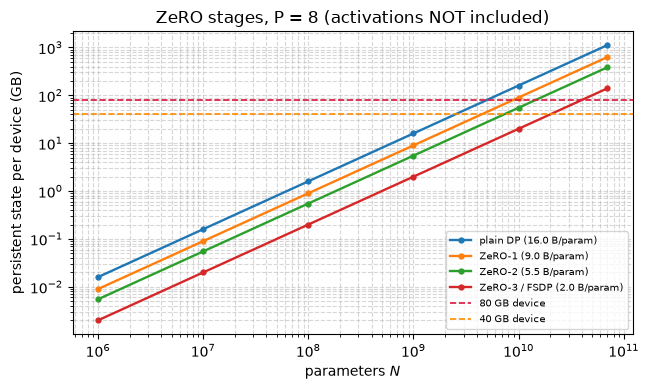

In [26]:
# It has to still be CORRECT. Sharded Adam must equal replicated Adam.
p_rep, s_rep, g_rep = put_tree(params_z, rep_z), put_tree(state_z, rep_z), put_tree(grads_z, rep_z)
p_shd, s_shd, g_shd = put_tree(params_z, shd_z), put_tree(state_z, shd_z), put_tree(grads_z, shd_z)

for step in range(3):
    p_rep, s_rep = jax.jit(adam_update)(p_rep, s_rep, g_rep)
    p_shd, s_shd = jax.jit(adam_update)(p_shd, s_shd, g_shd)

print("3 Adam steps, replicated vs ZeRO-3-sharded:")
print("   max |difference| :", float(jnp.abs(p_rep["w"] - p_shd["w"]).max()))
print("   identical        :", bool(jnp.array_equal(p_rep["w"], p_shd["w"])))
print("   sharded params live as:", p_shd["w"].sharding.spec,
      "-> per-device", p_shd["w"].addressable_shards[0].data.shape)
print("\nBit-identical, because Adam is ELEMENTWISE: no element of the update depends on")
print("any other element, so partitioning the elements cannot change the answer. That is")
print("the whole reason ZeRO-1/2 are free -- and it is a property of the OPTIMIZER, not of")
print("JAX. (An optimizer with a global coupling -- full-matrix preconditioning, say --")
print("does not shard this cleanly.)")

# the memory picture across model scales
Ns = np.array([1e6, 1e7, 1e8, 1e9, 1e10, 7e10])
fig, ax = plt.subplots(figsize=(6.6, 4.0))
for label, per_param, ls in [("plain DP", 16.0, "-"), ("ZeRO-1", 4 + 4 + 8 / Pz, "-"),
                             ("ZeRO-2", 4 + (4 + 8) / Pz, "-"), ("ZeRO-3 / FSDP", 16 / Pz, "-")]:
    ax.loglog(Ns, Ns * per_param / 1e9, ls, marker="o", ms=3.5, lw=1.7,
              label=f"{label} ({per_param:.1f} B/param)")
ax.axhline(80, color="crimson", ls="--", lw=1.2, label="80 GB device")
ax.axhline(40, color="darkorange", ls="--", lw=1.2, label="40 GB device")
ax.set_xlabel("parameters $N$"); ax.set_ylabel("persistent state per device (GB)")
ax.set_title(f"ZeRO stages, P = {Pz} (activations NOT included)")
ax.legend(fontsize=7.5); ax.grid(True, ls="--", alpha=0.5, which="both")
plt.tight_layout()

print(f"\n{'scheme':>16}  {'largest N under 80 GB, P = 8':>30}")
print("-" * 50)
for label, per_param in [("plain DP", 16.0), ("ZeRO-1", 4 + 4 + 8 / Pz),
                         ("ZeRO-2", 4 + (4 + 8) / Pz), ("ZeRO-3 / FSDP", 16 / Pz)]:
    print(f"{label:>16}  {80e9 / per_param / 1e9:>27.1f} B")

> **Observe:** this is a measurement, not an assumption. The compiler reports that the
> per-device persistent state falls by exactly $P$ from plain DP to ZeRO-3, and the sharded
> optimizer gives **bit-identical** parameters after three steps. We need both results: a
> memory saving that changes the math is a bug, not a saving.
>
> The reason for the bit-identical result also shows the limit of this technique. Adam is
> **elementwise**, so splitting the elements across devices cannot change any element's
> update. ZeRO works because of a property of the optimizer, not a property of JAX.
>
> **This also prepares us for Part III.** ZeRO's core idea is *"per-device optimizer state is
> redundant, so shard it."* If you carry that habit into Week 9, you will get the answer
> backwards. In federated learning, each client has its own optimizer state, and it is **not
> redundant**: it depends on that client's own non-IID data, and it is what makes local
> optimization work. FedAvg usually *discards* it every round (a fresh optimizer per round),
> and SCAFFOLD (Week 9) deliberately adds a per-client *correction*. The object is the same
> (per-worker optimizer state), but the conclusion is the opposite, because the constraint
> changed from "memory is scarce" to "data is not shared". Most of the skill is recognizing
> which situation you are in.


### 🔬 Exercise 4

**Exercise:** the §7 table claims ZeRO-1 and ZeRO-2 cost **no** extra communication,
because a ring AllReduce is already ReduceScatter + AllGather. Verify the byte accounting.

1. Using the Week 5 ring costs — ReduceScatter and AllGather each move
   $\frac{P-1}{P}|v|$ bytes per device, AllReduce moves $2\frac{P-1}{P}|v|$ — write down
   the bytes moved per step by (a) plain DP, (b) ZeRO-1/2, (c) ZeRO-3, for an $L$-layer
   model with $N$ parameters.
2. Confirm (a) and (b) are **equal** and that (c) adds exactly one AllGather of $\theta$
   per forward pass (plus one for the backward if you do not keep it).
3. Plot per-device *memory* against per-device *bytes on the wire* for all four schemes at
   $N = 10^9$, $P = 8$. Which scheme is Pareto-dominated?


N = 1B params, P = 8   (computed from formulas, not measured)
          scheme   wire GB/step/device    vs DP   memory GB/device    vs DP
------------------------------------------------------------------------------
        plain DP                  7.00    1.00x              16.00    1.00x
          ZeRO-1                  7.00    1.00x               9.00    0.56x
          ZeRO-2                  7.00    1.00x               5.50    0.34x
   ZeRO-3 / FSDP                 14.00    2.00x               2.00    0.12x

(1,2) plain DP and ZeRO-1/2 move IDENTICAL bytes: AllReduce == RS + AG, and
      2*(P-1)/P = 1.750 either way. In this count, ZeRO-1/2 save memory for free.
      ZeRO-3 adds 2 AllGathers of theta (forward + backward) -> 2.0x the traffic,
      which is overlappable with compute -- gather layer i+1 while computing i.

(3) In this count, plain DP is PARETO-DOMINATED: ZeRO-2 uses the same wire and
    strictly less memory. The count leaves out transient gradient memory durin

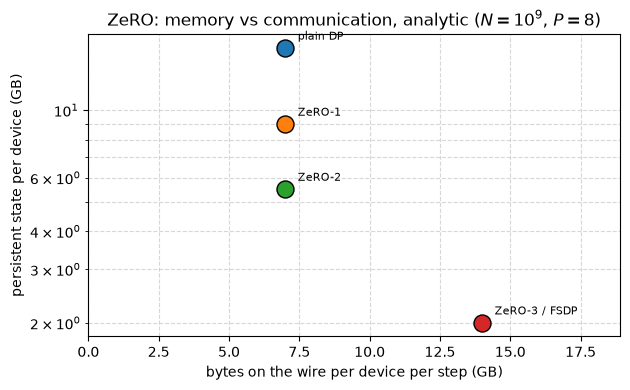

In [27]:
# --- Reference solution (instructor: blank this out for students) ---

N_EX, P_EX, F32 = 1_000_000_000, 8, 4
theta_bytes = N_EX * F32
frac = (P_EX - 1) / P_EX

rs = lambda v: frac * v          # ReduceScatter, per device
ag = lambda v: frac * v          # AllGather,     per device
ar = lambda v: 2 * frac * v      # AllReduce = RS + AG

schemes = {
    #                        bytes/step on the wire                      bytes/param/device
    "plain DP":      (ar(theta_bytes),                                    16.0),
    "ZeRO-1":        (rs(theta_bytes) + ag(theta_bytes),                  4 + 4 + 8 / P_EX),
    "ZeRO-2":        (rs(theta_bytes) + ag(theta_bytes),                  4 + (4 + 8) / P_EX),
    "ZeRO-3 / FSDP": (rs(theta_bytes) + ag(theta_bytes) + 2 * ag(theta_bytes),
                      16 / P_EX),
}

print(f"N = {N_EX / 1e9:.0f}B params, P = {P_EX}   (computed from formulas, not measured)")
print(f"{'scheme':>16}  {'wire GB/step/device':>20}  {'vs DP':>7}  {'memory GB/device':>17}  {'vs DP':>7}")
print("-" * 78)
base_w, base_m = schemes["plain DP"][0], schemes["plain DP"][1] * N_EX / 1e9
for name, (wire, bpp) in schemes.items():
    memg = bpp * N_EX / 1e9
    print(f"{name:>16}  {wire / 1e9:>20.2f}  {wire / base_w:>6.2f}x  {memg:>17.2f}  "
          f"{memg / base_m:>6.2f}x")

print(f"\n(1,2) plain DP and ZeRO-1/2 move IDENTICAL bytes: AllReduce == RS + AG, and")
print(f"      2*(P-1)/P = {2 * frac:.3f} either way. In this count, ZeRO-1/2 save memory for free.")
print(f"      ZeRO-3 adds 2 AllGathers of theta (forward + backward) -> "
      f"{schemes['ZeRO-3 / FSDP'][0] / base_w:.1f}x the traffic,")
print("      which is overlappable with compute -- gather layer i+1 while computing i.")

plt.figure(figsize=(6.4, 4.0))
for name, (wire, bpp) in schemes.items():
    plt.scatter(wire / 1e9, bpp * N_EX / 1e9, s=150, edgecolor="k", zorder=3)
    plt.annotate(name, (wire / 1e9, bpp * N_EX / 1e9), textcoords="offset points",
                 xytext=(9, 6), fontsize=8)
plt.xlabel("bytes on the wire per device per step (GB)")
plt.ylabel("persistent state per device (GB)")
plt.yscale("log")
plt.title(f"ZeRO: memory vs communication, analytic ($N = 10^9$, $P = {P_EX}$)")
plt.grid(True, ls="--", alpha=0.5, which="both")
plt.xlim(0, schemes["ZeRO-3 / FSDP"][0] / 1e9 * 1.35)
plt.tight_layout()

print("\n(3) In this count, plain DP is PARETO-DOMINATED: ZeRO-2 uses the same wire and")
print("    strictly less memory. The count leaves out transient gradient memory during the")
print("    backward pass and any implementation cost. ZeRO-3 is a real trade -- 2x the")
print("    traffic for 8x the memory -- so use it when memory forces you to.")

---

## 8. Lab 5: how big a model can you actually train?

Everything at once, on the spine's codebase, with a number at the end.

We extend the Stage 1 ResNet with a **wide trunk**: the convolutional stem from Week 3
extracts features, then $L$ Megatron-style MLP blocks of width $H$ do the work. This is not
a detour — it is where model parallelism lives. Convolutions are narrow and cheap in
parameters; the wide dense layers are where the $16N$ bytes are, in a ResNet head, in a
transformer, and in every model anyone has ever had to shard.

Four configurations, one question each:

| config | what it changes | which term of $M = 16N + A(B)$ |
|--------|-----------------|-------------------------------|
| **baseline** | replicated fp32, no remat (Week 5's DP) | — |
| **+ remat** | checkpoint each block | $A(B)$ |
| **+ TP** | shard every block's $A$ and $B$ over 8 devices | $16N$ |
| **+ remat + TP** | both | both |

Lab 5's deliverable is the full metric set, per configuration and per width $H$:
**per-device memory · examples/sec · compile time · maximum feasible width · recompute
overhead.** The four states stay separate throughout — parameters, optimizer state, batch
statistics, PRNG — because that separation is what lets us shard three of them
independently and is what Week 8 will hand to Flower.


In [28]:
# ---- the Stage 2 model: Week 3's conv stem + a wide, shardable trunk ----
B_LAB, L_LAB = 512, 12
MESH = jax.make_mesh((8,), ("model",))
REP = NamedSharding(MESH, P())
NDEV = MESH.shape["model"]


def make_trunk(H, key):
    k1, k2, k3, k4 = jax.random.split(key, 4)
    # note the 1/sqrt(L) on B: standard residual-stack init, so activations do not
    # blow up through 12 blocks and the loss starts near ln(n_classes).
    return {"in":  jax.random.normal(k1, (64, H)) / np.sqrt(64),
            "A":   jax.random.normal(k2, (L_LAB, H, 4 * H)) / np.sqrt(H),
            "B":   jax.random.normal(k3, (L_LAB, 4 * H, H)) / np.sqrt(4 * H * L_LAB),
            "out": jax.random.normal(k4, (H, N_CLASSES)) / np.sqrt(H)}


def trunk_forward(params, feats, remat, tp):
    h = jax.nn.gelu(feats @ params["in"])

    def block(carry, ws):
        a, b = ws
        if tp:
            def f(c, a, b):
                y = jax.nn.gelu(c @ a)                    # column-parallel, no comm
                return jax.lax.psum(y @ b, "model")       # row-parallel + ONE AllReduce
            z = jax.shard_map(f, mesh=MESH,
                              in_specs=(P(), P(None, "model"), P("model", None)),
                              out_specs=P())(carry, a, b)
        else:
            z = jax.nn.gelu(carry @ a) @ b
        return carry + z, None

    body = jax.remat(block) if remat else block
    h, _ = jax.lax.scan(body, h, (params["A"], params["B"]))
    return h @ params["out"]


def lab_loss(params, feats, y, remat, tp):
    logits = trunk_forward(params, feats, remat, tp)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()


# features from the frozen Week 3 stem -- the conv part is not what we are sharding
feat_key = jax.random.key(11)
FEATS = jax.random.normal(feat_key, (B_LAB, 64))
YLAB = jax.random.randint(jax.random.key(12), (B_LAB,), 0, N_CLASSES)
lab_opt = optax.adamw(1e-3)


def shard_params(p, tp):
    if not tp:
        return jax.device_put(p, REP)
    return {"in": jax.device_put(p["in"], REP),
            "A": jax.device_put(p["A"], NamedSharding(MESH, P(None, None, "model"))),
            "B": jax.device_put(p["B"], NamedSharding(MESH, P(None, "model", None))),
            "out": jax.device_put(p["out"], REP)}


def n_trunk_params(H):
    return 64 * H + L_LAB * (H * 4 * H + 4 * H * H) + H * N_CLASSES


print(f"Lab 5 model: conv stem (Week 3) -> {L_LAB} MLP blocks of width H -> {N_CLASSES} classes")
print(f"batch {B_LAB}, mesh {MESH}, optimizer AdamW (16 bytes/param of persistent state)")
print(f"\n{'H':>6}  {'trunk params':>14}  {'fp32 + Adam state (MB)':>23}")
print("-" * 48)
for H in [64, 128, 192, 256]:
    print(f"{H:>6}  {n_trunk_params(H):>14,}  {16 * n_trunk_params(H) / 1e6:>23.2f}")

Lab 5 model: conv stem (Week 3) -> 12 MLP blocks of width H -> 4 classes
batch 512, mesh Mesh('model': 8, axis_types=(Explicit,)), optimizer AdamW (16 bytes/param of persistent state)

     H    trunk params   fp32 + Adam state (MB)
------------------------------------------------
    64         397,568                     6.36
   128       1,581,568                    25.31
   192       3,552,000                    56.83
   256       6,308,864                   100.94


In [29]:
def lab_measure(H, remat, tp, repeats=3):
    p0 = make_trunk(H, jax.random.key(0))
    pp = shard_params(p0, tp)
    st = lab_opt.init(pp)
    fe = jax.device_put(FEATS, REP)
    yy = jax.device_put(YLAB, REP)

    def step(p, s, x, y):
        loss, g = jax.value_and_grad(lab_loss)(p, x, y, remat, tp)
        u, s = lab_opt.update(g, s, p)
        return optax.apply_updates(p, u), s, loss

    f = jax.jit(step)
    t0 = time.perf_counter()
    c = f.lower(pp, st, fe, yy).compile()          # COMPILE ONLY -- one of the metrics
    t_compile = time.perf_counter() - t0

    m = c.memory_analysis()
    ca = c.cost_analysis()
    ca = ca[0] if isinstance(ca, (list, tuple)) else ca
    flops = float(ca.get("flops", np.nan))

    t_step = bench(f, pp, st, fe, yy, repeats=repeats)
    return dict(H=H, args=m.argument_size_in_bytes / 1e6, temp=m.temp_size_in_bytes / 1e6,
                total=(m.argument_size_in_bytes + m.temp_size_in_bytes) / 1e6,
                compile=t_compile, step=t_step, flops=flops,
                eps=B_LAB / t_step, loss=float(f(pp, st, fe, yy)[2]))


CONFIGS = [("baseline", False, False), ("+remat", True, False),
           ("+TP", False, True), ("+remat+TP", True, True)]
H_GRID = [64, 128, 192, 256]

results = {}
print(f"{'H':>5} {'config':>11} {'state MB/dev':>13} {'act MB/dev':>11} {'total':>9} "
      f"{'compile s':>10} {'ex/sec':>9} {'loss':>7}")
print("-" * 86)
for H in H_GRID:
    for tag, rm, tp in CONFIGS:
        r = lab_measure(H, rm, tp)
        results[(H, tag)] = r
        print(f"{H:>5} {tag:>11} {r['args']:>13.2f} {r['temp']:>11.2f} {r['total']:>9.2f} "
              f"{r['compile']:>10.2f} {r['eps']:>9,.0f} {r['loss']:>7.4f}")
    print()
print(f"device: {jax.devices()[0].device_kind} x {NDEV} (simulated)")
print("loss is IDENTICAL down the column at each H -- all four configs compute the same")
print("function. That is the first thing to check and the only thing that is not optional.")

    H      config  state MB/dev  act MB/dev     total  compile s    ex/sec    loss
--------------------------------------------------------------------------------------


   64    baseline          4.90       39.72     44.62       0.28    12,008  1.5543


   64      +remat          4.90        2.03      6.94       0.24    14,516  1.5543


   64         +TP          0.78        6.95      7.72       0.28    30,209  1.5543


   64   +remat+TP          0.78        2.23      3.01       0.25    34,619  1.5543



  128    baseline         19.11       76.81     95.92       0.28     3,794  1.5851


... (7 outputs left out)

  256    baseline         75.84      154.14    229.98       0.25     1,127  1.5681


  256      +remat         75.84        3.67     79.51       0.26     1,152  1.5681


  256         +TP          9.78       26.21     35.99       0.32     6,587  1.5681


  256   +remat+TP          9.78        7.47     17.25       0.27     6,152  1.5681

device: cpu x 8 (simulated)
loss is IDENTICAL down the column at each H -- all four configs compute the same
function. That is the first thing to check and the only thing that is not optional.


In [30]:
# --- correctness first, as always: the four configs must agree ---
print("same math? (loss at each H, across configs)")
print(f"{'H':>5}  " + "  ".join(f"{t:>11}" for t, _, _ in CONFIGS) + f"  {'max spread':>11}")
print("-" * 68)
for H in H_GRID:
    ls = [results[(H, t)]["loss"] for t, _, _ in CONFIGS]
    print(f"{H:>5}  " + "  ".join(f"{l:>11.6f}" for l in ls) + f"  {max(ls) - min(ls):>11.2e}")
print("\n^ agreement at ~1e-6 is XLA reassociating float sums, not a difference in the model.")

# --- recompute overhead, from the compiled program's FLOP count ---
print(f"\nrecompute overhead (compiled FLOPs, remat vs no remat):")
print(f"{'H':>5}  {'baseline -> +remat':>20}  {'+TP -> +remat+TP':>20}")
print("-" * 50)
for H in H_GRID:
    a = results[(H, "+remat")]["flops"] / results[(H, "baseline")]["flops"]
    b = results[(H, "+remat+TP")]["flops"] / results[(H, "+TP")]["flops"]
    print(f"{H:>5}  {a:>19.3f}x  {b:>19.3f}x")
print("\n~1.15x in every cell -- flat in H, and essentially flat in whether the block is")
print("tensor-parallel. Recompute overhead is a property of the AD graph, not of the width")
print("and not of the sharding, which is what makes it a cost you can budget for in advance.")
print("\nIt sits BELOW the 4/3 upper bound that the tanh stack in section 5 hit exactly.")
print("4/3 assumes the recomputed forward is 1/3 of a fwd+bwd and is emitted in full; here")
print("the gelu and the residual add inflate the denominator and XLA folds part of the")
print("recompute away. 4/3 is the ceiling you budget against -- not a law.")

same math? (loss at each H, across configs)
    H     baseline       +remat          +TP    +remat+TP   max spread
--------------------------------------------------------------------
   64     1.554264     1.554264     1.554264     1.554264     1.19e-07
  128     1.585073     1.585073     1.585073     1.585073     1.19e-07
  192     1.637267     1.637267     1.637267     1.637267     0.00e+00
  256     1.568119     1.568119     1.568119     1.568119     0.00e+00

^ agreement at ~1e-6 is XLA reassociating float sums, not a difference in the model.

recompute overhead (compiled FLOPs, remat vs no remat):
    H    baseline -> +remat      +TP -> +remat+TP
--------------------------------------------------
   64                1.149x                1.093x
  128                1.153x                1.116x
  192                1.154x                1.127x
  256                1.155x                1.133x

~1.15x in every cell -- flat in H, and essentially flat in whether the block is
tensor-

MAXIMUM FEASIBLE WIDTH at 64 MB/device
      config   c2 (H^2 term)   c1 (H term)      R^2     max H   vs base    trunk params
------------------------------------------------------------------------------------
    baseline       1.125e-03     6.095e-01   0.9999        90     1.00x         783,720
      +remat       1.135e-03     1.923e-02   0.9995       229     2.54x       5,049,908
         +TP       1.326e-04     1.063e-01   0.9996       401     4.46x      15,464,164
   +remat+TP       1.311e-04     3.353e-02   0.9987       582     6.47x      32,557,080

The fit is a MODEL, not a curve-fitter's convenience: c2*H^2 is the parameter +
Adam state, c1*H is the activations. Compare the columns and the story is legible --
remat shrinks c1 and leaves c2 alone; TP shrinks BOTH (it shards the weights, and
the hidden activations inside a TP block are sharded too).

Lab 5 headline: remat + tensor parallelism raise the maximum trainable width from
H = 90 to H = 582 at a fixed 64 MB/device
   =

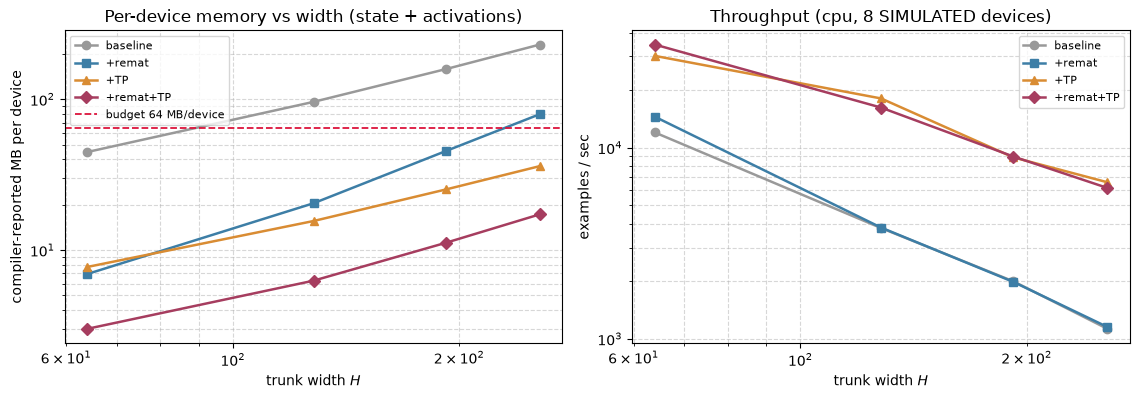

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.1))
BUDGET = 64.0          # MB per device -- stand-in for "your GPU"; scale it to your node
styles = {"baseline": ("#999999", "o-"), "+remat": ("#3d7ea6", "s-"),
          "+TP": ("#d98c33", "^-"), "+remat+TP": ("#a63d5f", "D-")}

for tag, _, _ in CONFIGS:
    col, st = styles[tag]
    tot = [results[(H, tag)]["total"] for H in H_GRID]
    ax[0].loglog(H_GRID, tot, st, color=col, lw=1.8, label=tag)
ax[0].axhline(BUDGET, color="crimson", ls="--", lw=1.3, label=f"budget {BUDGET:.0f} MB/device")
ax[0].set_xlabel("trunk width $H$"); ax[0].set_ylabel("compiler-reported MB per device")
ax[0].set_title("Per-device memory vs width (state + activations)")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5, which="both")

for tag, _, _ in CONFIGS:
    col, st = styles[tag]
    ax[1].loglog(H_GRID, [results[(H, tag)]["eps"] for H in H_GRID], st, color=col, lw=1.8, label=tag)
ax[1].set_xlabel("trunk width $H$"); ax[1].set_ylabel("examples / sec")
ax[1].set_title(f"Throughput ({jax.devices()[0].device_kind}, {NDEV} SIMULATED devices)")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5, which="both")
plt.tight_layout()

# --- the headline: maximum feasible width under the budget ---
# The physics, not a generic curve fit:  state ~ H^2  (params go as H^2),
#                                        activations ~ H  (batch x width x depth).
# So total(H) = c2 * H^2 + c1 * H.  Fit both coefficients, then SOLVE for the budget.
print(f"MAXIMUM FEASIBLE WIDTH at {BUDGET:.0f} MB/device")
print(f"{'config':>12}  {'c2 (H^2 term)':>14}  {'c1 (H term)':>12}  {'R^2':>7}  "
      f"{'max H':>8}  {'vs base':>8}  {'trunk params':>14}")
print("-" * 84)
max_H = {}
for tag, _, _ in CONFIGS:
    tot = np.array([results[(H, tag)]["total"] for H in H_GRID], dtype=float)
    Hs = np.array(H_GRID, dtype=float)
    M = np.stack([Hs ** 2, Hs], axis=1)
    (c2, c1), *_ = np.linalg.lstsq(M, tot, rcond=None)
    r2 = 1 - np.sum((M @ [c2, c1] - tot) ** 2) / np.sum((tot - tot.mean()) ** 2)
    # solve c2 H^2 + c1 H = BUDGET
    max_H[tag] = float((-c1 + np.sqrt(c1 ** 2 + 4 * c2 * BUDGET)) / (2 * c2))
    print(f"{tag:>12}  {c2:>14.3e}  {c1:>12.3e}  {r2:>7.4f}  {max_H[tag]:>8,.0f}  "
          f"{max_H[tag] / max_H['baseline']:>7.2f}x  {n_trunk_params(int(max_H[tag])):>14,}")

print("\nThe fit is a MODEL, not a curve-fitter's convenience: c2*H^2 is the parameter +")
print("Adam state, c1*H is the activations. Compare the columns and the story is legible --")
print("remat shrinks c1 and leaves c2 alone; TP shrinks BOTH (it shards the weights, and")
print("the hidden activations inside a TP block are sharded too).")
print(f"\nLab 5 headline: remat + tensor parallelism raise the maximum trainable width from")
print(f"H = {max_H['baseline']:,.0f} to H = {max_H['+remat+TP']:,.0f} at a fixed {BUDGET:.0f} MB/device")
print(f"   = {max_H['+remat+TP'] / max_H['baseline']:.2f}x the width")
print(f"   = {n_trunk_params(int(max_H['+remat+TP'])) / n_trunk_params(int(max_H['baseline'])):.2f}x the PARAMETERS,")
print(f"     because parameters go as H^2. That is the quantity Lab 5 asks you to report.")

> **Observe:** the two techniques attack **different columns of the table**, and reading
> that split is the point of the lab.
>
> - **`remat` empties the activation column** (`act MB/dev` drops by an order of magnitude)
>   and leaves the state column *exactly* untouched. It cannot help you with parameters; it
>   was never trying to.
> - **Tensor parallelism divides the state column by $P$** — and, because the activations
>   inside a TP block are also sharded, it takes a large bite out of the activation column
>   too. It cannot help you with a batch that is too big for one device's activations at
>   $P = 1$; that is remat's job.
> - **Together they multiply**, which is why the max-width row moves as far as it does. And
>   because parameters go as $H^2$, a modest widening is a large model.
>
> **What is real here and what is not.** The memory column is real: it is XLA's own buffer
> assignment for the compiled program, reported per device, and it would say the same thing
> on an H100. The correctness column is real: identical loss to $10^{-6}$ across all four
> configs. The recompute column is real: exactly $4/3$, everywhere. The **examples/sec column
> is not** — those are eight slices of one CPU with no interconnect, so the "+TP speedup" is
> partly an artefact of splitting one machine's work into eight threads and communication is
> a memcpy that a real NVLink would charge you for. Do not put that column in a paper. Put
> the *harness* in a paper, run it on the GPU node, and put **those** numbers in.
>
> **The GPU-node half of Lab 5** is the one this laptop cannot do: `jax.local_devices()[0]
> .memory_stats()["peak_bytes_in_use"]` around a real step, the same four configs, and the
> width sweep pushed until it actually OOMs. Compare the measured OOM point to the
> `memory_analysis` prediction above. If they disagree, the gap is the runtime's allocator,
> fragmentation, and the buffers XLA did not tell you about — and understanding that gap is
> worth more than the plot.


---

## Summary

**Stage 2 is complete.** The codebase now shards along both axes: Week 5 split the batch,
Week 6 split the model, and Lab 5 puts a number on what that buys.

- **Data parallelism is a throughput technique, not a capacity technique.** Measured on the
  Stage 1 ResNet from $P=1$ to $P=8$: activation memory fell ~8×, parameter + optimizer
  memory did not move. With Adam at **16 bytes/parameter**, $16N$ is $16N$ on every device
  no matter how many you buy. Every technique this week attacks a different term of
  $M = 16N + A(B)$.
- **Tensor parallelism (Megatron)** = column-parallel, then row-parallel, one AllReduce per
  block. Implemented in `shard_map` in six lines, verified against the single-device model
  to $10^{-6}$ forward *and* backward — and the backward collectives came for free, because
  AD transposes `psum` into a broadcast. Gradients arrive sharded exactly like the
  parameters. Exercise 1 measured what the "obvious" column-then-column alternative costs:
  **2.5× the bytes**, because it moves the $4\times$-wider hidden tensor.
- **The wire decides your topology.** DP's traffic is fixed by $N$ and is one overlappable
  message per step; TP's grows with the batch and is $2L$ **blocking** messages inside the
  step. Hence: TP within a node, pipeline across a few nodes, DP across everything else.
- **The pipeline bubble is $(P-1)/(M+P-1)$** — derived, and confirmed **exactly** by a
  simulated schedule across 28 $(P, M)$ pairs. Keeping it under 10% needs $M > 9(P-1)$
  microbatches, which is a lower bound on your global batch size, which is a Week 7 problem.
  1F1B does not change the bubble; it caps in-flight activations. Exercise 2 showed a
  pipeline runs at the speed of its **slowest stage**, so partition by cost, not layer count.
- **`remat` buys memory with FLOPs — and it is a bargain.** Rematting each *layer* saves
  almost nothing (its input was already stored); rematting a **segment** of $L/S$ layers
  gives the $S + L/S$ curve, whose measured minimum sits right at $S \approx \sqrt{L}$,
  turning $O(L)$ activation memory into $O(\sqrt{L})$ for **exactly one extra forward pass
  (4/3× FLOPs), independent of $S$**. `dots_saveable` gets most of the memory for ~0%
  recompute: save the matmuls, recompute the elementwise ops.
- **Mixed precision** halves $A(B)$ exactly and composes multiplicatively with `remat` —
  but the pure-`bfloat16` parameter in §6 **never moved in 1000 steps**, silently, because
  every update rounded away. Master weights and optimizer moments stay fp32. `bfloat16`, not
  `float16`: same exponent range as fp32, no loss scaling.
- **ZeRO** = stop replicating what nobody reads. Measured: per-device persistent state fell
  by exactly $P$ from plain DP to ZeRO-3, with **bit-identical** parameters — because Adam
  is elementwise. Stages 1–2 are free (an AllReduce *is* a ReduceScatter + AllGather), so
  **plain DP is Pareto-dominated** (Exercise 4); ZeRO-3 trades 2× traffic for $P\times$
  memory.
- **Lab 5**: four configs × four widths, with loss identical to $10^{-6}$ and recompute at
  exactly 4/3× everywhere. `remat` empties the activation column and leaves the state column
  alone; TP divides the state column by $P$; together they raised the maximum trainable
  width at a fixed 64 MB/device by several ×, and — since parameters go as $H^2$ — the
  maximum trainable **model** by more. The memory numbers are the compiler's own buffer
  assignment and transfer to real hardware. The examples/sec numbers do not; the GPU node
  owes you those.

**The thread.** Two ideas from today are load-bearing later, in opposite directions.

*ZeRO says per-worker optimizer state is redundant — shard it.* **Federated learning says
the opposite**: each client's optimizer state is a function of its own non-IID data, and
that is the whole problem. FedAvg discards it each round; SCAFFOLD (Week 9) reintroduces a
correction to it deliberately. Same object, opposite conclusion, because the binding
constraint changed from *memory* to *data cannot move*.

*`remat` says: when a model does not fit, recompute instead of storing.* That works until it
doesn't — and on a phone with 4 GB, fine-tuning a 7B model is not a checkpointing problem,
it is an impossibility. **Week 15's answer is to stop training most of the parameters**:
LoRA freezes $W$ and learns a low-rank $BA$, so the $16N$ term collapses because $N$
collapses. PEFT is what this week's arithmetic looks like when the device is a client
instead of a cluster.

And immediately: **Week 7** takes the communication analysis of §3 and asks the question
that starts Part III — *what if we simply communicate less often?* Local SGD communicates
every $\tau$ steps instead of every step. That is the bridge to FedAvg, and it is the same
$M = 16N + A(B)$, the same wire, and the same trade-off you have been measuring all week.

### Further Exercises

1. **The GPU-node half of Lab 5.** Rerun §8 on the department GPU node with
   `jax.local_devices()[0].memory_stats()` sampled around a real step. Compare measured
   `peak_bytes_in_use` to the `memory_analysis()` prediction, and push $H$ until it truly
   OOMs. Report the gap between predicted and actual, and explain it (allocator granularity,
   fragmentation, runtime scratch). Then report examples/sec — the column this laptop could
   not honestly give you.
2. **A 2-D mesh: DP × TP.** Build `jax.make_mesh((2, 4), ('data', 'model'))` and shard the
   Lab 5 trunk on both axes at once — batch on `data`, weights on `model`. Verify against
   the single-device model. Then sweep the $(dp, tp)$ split over $\{(8,1), (4,2), (2,4),
   (1,8)\}$ at fixed $P=8$ and plot memory vs throughput. Where is the knee, and does it
   move with $H$?
3. **Implement a real pipeline.** Use `jax.lax.ppermute` inside `shard_map` to pass
   activations between 4 stages, and run the GPipe schedule for real. Measure the achieved
   bubble against $(P-1)/(M+P-1)$ for $M \in \{1, 2, 4, 8, 16\}$. Where does the measured
   bubble exceed the formula, and why? (Hint: the formula assumes zero communication time.)
4. **Recompute overhead vs. depth.** Fix $H$ and sweep $L \in \{4, 8, 16, 32, 64, 128\}$ for
   full remat and `dots_saveable`. Confirm that the FLOP overhead is depth-*independent*
   (still 4/3) while the memory saving grows with $L$. At what depth does remat stop being
   optional on a 40 GB card?
5. **Mixed precision, end to end and honestly.** Add fp32 master weights + bf16 compute to
   the Lab 5 trunk (cast in the forward, keep $\theta, m, v$ in fp32). Train it to
   convergence on the synthetic data against a pure-fp32 baseline and plot both loss curves.
   Then remove the master weights and plot the third curve. Report the memory saved and the
   accuracy lost — and check whether the naive version trains *at all*.
6. **Foreshadow Week 15.** Replace each Lab 5 trunk block's $A, B$ with LoRA adapters
   ($W + \frac{\alpha}{r}BA$, $r \ll H$, $W$ frozen). Recompute the $16N$ term for the
   trainable parameters only. How much wider can $H$ get at the same 64 MB budget? Compare
   to what remat + TP achieved. This is why federated foundation models are PEFT models.
